<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-06/lab-025-cvae-physics.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 025 <br>
<hr/>
# Lab 025 — Spin configurations from a conditional VAE

A conditional variational autoencoder (cVAE, Lab 024) produces new configurations of a spin model at a requested temperature $T$, or at a
requested point $(g,T)$ of a phase diagram. A generated snapshot can *look* like a Monte Carlo snapshot and still violate the physics fixed by
the Hamiltonian. In this lab we therefore test the synthetic data in two independent ways. The first test uses networks trained on real
Monte Carlo data, a regressor that reads $T$ from a snapshot and classifiers of the phase: they tell us whether the synthetic snapshots
carry the patterns that a network has learned to associate with a temperature or a phase. The second test uses the Hamiltonian itself: from
the snapshots we compute the energy, the magnetisation, the specific heat, the susceptibility, the Binder cumulant, the distributions $P(e)$ and
$P(m)$ and the correlation function, and compare them with their Monte Carlo values.

What the generator can and cannot get right follows from how it samples. Generating "at temperature $T$" means drawing a latent vector
$\mathbf z$ and then every spin independently from its own probability: given $\mathbf z$ the generator is a product over sites, a
mean-field-like distribution, whereas Monte Carlo runs a Markov chain whose stationary distribution is exactly the Boltzmann distribution,
with all the correlations between neighbouring spins that the Hamiltonian implies. Section 2 explains this, and Section 3.6 shows the two
samplers side by side. It is the reason why the order parameter will be reproduced and the energy will not.

Every test is run first on held-out real data, which fixes the baseline and the statistical noise of the estimate, and then, identically, on
synthetic data at the same conditions. Before turning to the physics we make sure that the generator itself is trained properly, by looking
at the training curves, the active latent units, a classifier two-sample test and possible memorisation of the training set.

We work with two models and the Monte Carlo data of Lab 018: the 2D Ising model with $L=30$ (Section 3) and the frustrated $J_1$–$J_2$ Ising
model with $L=32$ (Section 4). Before running the notebook, run Lab 018 and copy `ising_L30.npz` and `j1j2_L32.npz` into `data/`; everything
runs on the CPU.

## 1. Hamiltonian, Boltzmann distribution and observables

We start by recalling what a "correct" sample of a spin model is. A classical spin model assigns an energy $H(\mathbf s)$ to every
configuration $\mathbf s=(s_1,\dots,s_N)$, $s_i=\pm1$, on an $L\times L$ lattice with periodic boundaries ($N=L^2$):
$$
\text{Ising: } H=-J\sum_{\langle ij\rangle}s_is_j,\qquad
J_1\text{–}J_2:\ H=-J_1\sum_{\langle ij\rangle}s_is_j+J_2\sum_{\langle\langle ij\rangle\rangle}s_is_j ,
$$
with $\langle ij\rangle$ nearest neighbours and $\langle\langle ij\rangle\rangle$ diagonal neighbours; we set $J=J_1=1$ and $k_B=1$. In thermal
equilibrium at temperature $T$ (inverse temperature $\beta=1/T$) a configuration occurs with the Boltzmann probability
$$
p(\mathbf s)=\frac{e^{-\beta H(\mathbf s)}}{Z},\qquad Z=\sum_{\mathbf s}e^{-\beta H(\mathbf s)} .
$$
At low $T$ the low-energy, ordered configurations dominate; at high $T$ all configurations become nearly equally likely and the system is
disordered.

Every observable we use is an average over this distribution: for a quantity $O(\mathbf s)$ of a single configuration,
$$
\langle O\rangle=\frac1Z\sum_{\mathbf s}O(\mathbf s)\,e^{-\beta H(\mathbf s)} .
$$
The partition function also generates the thermodynamics: the energy per spin is the first derivative of $\ln Z$ with respect to $\beta$, and
the specific heat per spin is the second derivative, which equals the variance of the energy,
$$
\begin{aligned}
\langle e\rangle&=\frac{\langle H\rangle}{N}=-\frac1N\,\frac{\partial\ln Z}{\partial\beta},\\
c&=\frac{\beta^2}{N}\,\frac{\partial^2\ln Z}{\partial\beta^2}=\frac{\beta^2}{N}\big(\langle H^2\rangle-\langle H\rangle^2\big)
=N\beta^2\big(\langle e^2\rangle-\langle e\rangle^2\big).
\end{aligned}
$$
The sums run over all $2^N$ configurations and cannot be performed for $N=900$ or $N=1024$. Monte Carlo instead draws $n$ configurations
$\mathbf s^{(1)},\dots,\mathbf s^{(n)}$ with probability $p(\mathbf s)$ at each temperature, and every average $\langle O\rangle$ is estimated by
the plain sample mean $\overline{O}=\frac1n\sum_{k=1}^n O(\mathbf s^{(k)})$. A generator is judged by computing exactly the same sample means
over its own configurations. The table lists each observable in both forms: the definition through the Boltzmann distribution, and the
estimator that the functions `ising_observables` and `j1j2_observables` below compute. Here $e_k=H(\mathbf s^{(k)})/N$ and
$m_k=\frac1N\sum_i s_i^{(k)}$ are the energy and magnetisation per spin of sample $k$, $\overline{x}$ is the mean over the $n$ samples, and on a
finite lattice without a field $\langle m\rangle=0$ by the symmetry $\mathbf s\to-\mathbf s$, which is why $|m|$ is used.

| observable | definition through $Z$ | estimator from $n$ samples (as in the code) | physical meaning |
|---|---|---|---|
| energy per spin | $\langle e\rangle=-\frac1N\partial_\beta\ln Z$ | $\overline{e}=\frac1n\sum_k e_k$ | counts satisfied and broken bonds (local structure) |
| magnetisation | $\langle\lvert m\rvert\rangle=\frac1Z\sum_{\mathbf s}\lvert m(\mathbf s)\rvert e^{-\beta H}$ | $\overline{\lvert m\rvert}=\frac1n\sum_k\lvert m_k\rvert$ | ferromagnetic order (large below $T_c$, small above) |
| stripe order ($J_1$–$J_2$) | $\langle m_{\rm str}\rangle$, $m_{\rm str}=\sqrt{m_{(\pi,0)}^2+m_{(0,\pi)}^2}$, $m_{(\pi,0)}=\frac1N\sum_{\mathbf x}(-1)^{x}s_{\mathbf x}$ | $\overline{m_{\rm str}}=\frac1n\sum_k m_{{\rm str},k}$ | spins alternating along one lattice direction |
| specific heat | $c=N\beta^2\big(\langle e^2\rangle-\langle e\rangle^2\big)$ | $N\beta^2\big(\overline{e^2}-\overline{e}^{\,2}\big)$ | energy fluctuations, peaks at a transition |
| susceptibility | $\chi=N\beta\big(\langle m^2\rangle-\langle\lvert m\rvert\rangle^2\big)$ | $N\beta\big(\overline{m^2}-\overline{\lvert m\rvert}^{\,2}\big)$ | magnetisation fluctuations, peaks at a transition |
| Binder cumulant | $U_4=1-\dfrac{\langle m^4\rangle}{3\langle m^2\rangle^2}$ | $1-\dfrac{\overline{m^4}}{3\,\overline{m^2}^{\,2}}$ | shape of $P(m)$: $2/3$ for two sharp peaks, $\to0$ for a Gaussian |
| correlation function | $G(r)=\frac{1}{2N}\sum_{\mathbf x}\sum_{\mu=1,2}\langle s_{\mathbf x}s_{\mathbf x+r\hat e_\mu}\rangle$ | $\frac{1}{2nN}\sum_k\sum_{\mathbf x}\sum_{\mu}s^{(k)}_{\mathbf x}s^{(k)}_{\mathbf x+r\hat e_\mu}$ | how far order extends ($\hat e_\mu$: lattice unit vectors) |
| distributions | $P(e')=\frac1Z\sum_{\mathbf s}\delta\big(e'-H(\mathbf s)/N\big)e^{-\beta H}$, same for $P(m')$ | histograms of $e_k$ and of $m_k$ | full fluctuations, not only means |

For $J_1$–$J_2$ the energy per spin includes the diagonal bonds, $e_k=\frac1N H(\mathbf s^{(k)})$ with the Hamiltonian above, and $m_{(0,\pi)}$ is
defined like $m_{(\pi,0)}$ with $(-1)^{y}$; the larger of the two tells which stripe orientation a snapshot has. All variances are the
population variances (division by $n$), as computed by `numpy.var`.

For the 2D Ising model the transition temperature is known exactly from Onsager's solution: $T_c=2/\ln(1+\sqrt2)\approx2.269$.

## 2. Conditional VAE for spins

The generator is the conditional variational autoencoder (cVAE) of Lab 024, with a spin configuration in place of an image and the temperature in place of the digit. A configuration $\mathbf s=(s_1,\dots,s_N)$, $s_i=\pm1$, is stored as bits $b_i=(s_i+1)/2\in\{0,1\}$, and the condition is $c=T$ for the Ising model and $c=(g,T)$ for the $J_1$–$J_2$ model. What we train are three pieces. The prior $p(\mathbf z)=\mathcal N(0,I)$ over a latent vector $\mathbf z\in\mathbb R^{d}$, $d=16$ (later also a learned prior $p_\psi(\mathbf z|c)$). The decoder, a network that outputs one logit $\ell_i(\mathbf z,c)$ per site and treats the spins as independent Bernoulli variables given $\mathbf z$,
$$
p_\theta(\mathbf s\mid\mathbf z,c)=\prod_{i=1}^N \sigma(\ell_i)^{b_i}\,\big(1-\sigma(\ell_i)\big)^{1-b_i},\qquad \sigma(\ell)=\frac1{1+e^{-\ell}},
$$
so that $\sigma(\ell_i)$ is the probability that spin $i$ points up. And the encoder $q_\phi(\mathbf z\mid\mathbf s,c)=\mathcal N\big(\boldsymbol\mu(\mathbf s,c),\mathrm{diag}\,\boldsymbol\sigma^2(\mathbf s,c)\big)$, which proposes the latent vectors that could have produced a given configuration.

Training should make the log-likelihood $\log p_\theta(\mathbf s\mid c)$ of the Monte Carlo configurations large, but this quantity is an integral over all latent vectors and cannot be computed. We therefore maximise the evidence lower bound (ELBO), a quantity that can be computed and is never larger ("evidence" is the traditional name of $p_\theta(\mathbf s\mid c)$; the derivation is given in Lab 024). For every training configuration
$$
\log p_\theta(\mathbf s\mid c)\;\ge\;\mathbb E_{q_\phi(\mathbf z|\mathbf s,c)}\big[\log p_\theta(\mathbf s\mid\mathbf z,c)\big]\;-\;
\mathrm{KL}\big(q_\phi(\mathbf z\mid\mathbf s,c)\,\|\,p(\mathbf z)\big)\;=\;\mathrm{ELBO}.
$$
The first term is minus the binary cross-entropy (BCE) between the bits and the predicted probabilities,
$$
-\log p_\theta(\mathbf s\mid\mathbf z,c)=\mathrm{BCE}=-\sum_{i=1}^N\Big[b_i\log\sigma(\ell_i)+(1-b_i)\log\big(1-\sigma(\ell_i)\big)\Big],
$$
the number of nats by which the predicted spin probabilities fail to explain the configuration: 0 if every spin is predicted with certainty, $N\log2=624$ nats for $N=900$ if every spin is a coin flip. The second term is the Kullback–Leibler (KL) divergence $\mathrm{KL}(q\|p)=\mathbb E_q[\log q-\log p]\ge0$ between the encoder cloud and the prior; for two diagonal Gaussians it is
$$
\mathrm{KL}=\frac12\sum_{j=1}^{d}\big(\sigma_j^2+\mu_j^2-1-\log\sigma_j^2\big),
$$
zero when the cloud equals the prior and growing with the information the latent vector carries about the configuration. We minimise $-\mathrm{ELBO}$ averaged over the data, sampling $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\epsilon$ with $\boldsymbol\epsilon\sim\mathcal N(0,I)$ (the reparametrisation trick).

Generating "at temperature $T$" uses only the prior and the decoder. We draw $\mathbf z$ from the prior, compute the logits $\ell_i(\mathbf z,T)$, and draw every spin independently, $s_i=+1$ with probability $\sigma(\ell_i)$. Alternatively, we can take the most likely configuration $\hat s_i=\mathrm{sign}\,\ell_i$. The model distribution is
$p_\theta(\mathbf s\mid T)=\int d\mathbf z\,p(\mathbf z)\,p_\theta(\mathbf s\mid\mathbf z,T)$, and it should approximate the Boltzmann distribution $e^{-\beta H(\mathbf s)}/Z$. At fixed $\mathbf z$, however, the decoder is a product over sites, the same structure as a mean-field ansatz: $\langle s_i\rangle_{\mathbf z}=\tanh(\ell_i/2)$ and
$$
\langle s_is_j\rangle_{\mathbf z}=\tanh(\ell_i/2)\tanh(\ell_j/2)\quad (i\neq j),\qquad
\mathrm{Cov}(s_i,s_j)=\mathrm{Cov}_{\mathbf z}\big(\tanh(\ell_i/2),\tanh(\ell_j/2)\big).
$$
All correlations between spins must therefore be carried by the 16 latent variables. A global property such as the magnetisation is a single number per configuration and can be encoded in $\mathbf z$, which is the macrostate-microstate picture of Lab 024. The energy $H=-J\sum_{\langle ij\rangle}s_is_j$ is a sum of nearest-neighbour correlations, and every spin whose probability is not saturated near 0 or 1 is drawn independently of its neighbours and breaks its bonds at random.

Monte Carlo sampling works differently. It runs a Markov chain: starting from some configuration, it repeatedly proposes a change (a single spin flip in the Metropolis algorithm, accepted with probability $\min(1,e^{-\beta\Delta H})$; a flip of whole clusters in the Swendsen–Wang algorithm that produced the data of this lab) and accepts or rejects it with rules built from $H$ itself. The stationary distribution of this chain is exactly $e^{-\beta H}/Z$, so after equilibration every snapshot is a sample of the Boltzmann distribution, with all the correlations between neighbouring spins that $H$ implies. The price is time: the chain must be equilibrated, and successive snapshots are correlated. The cVAE needs no $H$ and produces an independent configuration in one forward pass, but it can only reproduce what its structure can represent. This is why the energy, the specific heat and $G(r)$ are the sharp tests in this lab, while the order parameter is expected to be easier. Section 3.6 shows the two samplers side by side.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # must be set before jax is imported
import time, json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import jax, jax.numpy as jnp
import optax
from flax import nnx

T_START = time.time()
print("JAX", jax.__version__, "| devices:", jax.devices())
navy, blue, orange, grey, green = "#002B5C", "#005CA7", "#D35A05", "#8A929E", "#2E8B57"
SPIN = ListedColormap(["#FFFFFF", navy])                  # s = -1 white, s = +1 navy
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.5, "figure.dpi": 150}
SPIN_GREY = LinearSegmentedColormap.from_list("spin_grey", ["#FFFFFF", navy])  # probability 0 white, 1 navy
OUT, DATA = "../beamer/figures", "data"
os.makedirs(OUT, exist_ok=True)
NUMBERS = {}                                              # every number quoted on the slides is stored here
def save(fig, name):
    fig.savefig(f"{OUT}/{name}", dpi=300, bbox_inches="tight", pad_inches=0.02)
TC = 2.0 / np.log(1.0 + np.sqrt(2.0))                     # Onsager: T_c = 2.2692 (J = k_B = 1)

def unpack_spins(packed, L):
    '''Packed bits (..., L, ceil(L/8)) uint8  ->  spins (..., L, L) int8 with values -1, +1.'''
    bits = np.unpackbits(packed, axis=-1, count=L)       # (..., L, L) in {0, 1}
    return bits.astype(np.int8) * 2 - 1

JAX 0.11.0 | devices: [CpuDevice(id=0)]


<hr/>
## 3. The 2D Ising model

### 3.1 Monte Carlo data

The file `ising_L30.npz` holds 256 Swendsen–Wang configurations at each of 37 temperatures, $T\in[1.5,3.5]$, sampled more densely near $T_c$.
At every temperature we split them into three sets. The 128 configurations of `S_train` are the training set both of the generator and of the
evaluator networks. The remaining configurations form two independent held-out real sets, `S_A` and `S_B`, of 64 snapshots each. `S_A` is the
reference for every test, while the difference between `S_A` and `S_B` measures the statistical noise of a 64-snapshot estimate; we call it the
real-vs-real baseline. All arrays have the shape `(n_T, n, L, L)`, that is (temperatures, snapshots, rows, columns).

In [2]:
data = np.load(f"{DATA}/ising_L30.npz")
L = int(data["L"]); N = L * L
order = np.argsort(data["T"])
T_grid = data["T"][order]                                  # (37,)
S_all = unpack_spins(data["configs"], L)[order]            # (37, 256, 30, 30) int8
n_T, n_per_T = S_all.shape[:2]

rng = np.random.default_rng(0)
perm = rng.permutation(n_per_T)                            # the same random split at every temperature
S_train = S_all[:, perm[:128]]                             # (37, 128, 30, 30)
S_A = S_all[:, perm[128:192]]                              # (37, 64, 30, 30)  held-out reference
S_B = S_all[:, perm[192:]]                                 # (37, 64, 30, 30)  second held-out set (noise level)
assert S_train.shape == (n_T, 128, L, L) and S_A.shape == S_B.shape == (n_T, 64, L, L)
i_c = int(np.argmin(np.abs(T_grid - TC)))                  # grid temperature closest to T_c
print(f"{n_T} temperatures, T from {T_grid[0]} to {T_grid[-1]}; closest to T_c = {TC:.4f}: T = {T_grid[i_c]}")
print(f"per temperature: {S_train.shape[1]} training, {S_A.shape[1]} + {S_B.shape[1]} held-out real configurations")

37 temperatures, T from 1.5 to 3.5; closest to T_c = 2.2692: T = 2.26
per temperature: 128 training, 64 + 64 held-out real configurations


### 3.2 Observables fixed by the Hamiltonian

We now turn the observables of Section 1 into formulas for a finite set of snapshots. For one snapshot, with each nearest-neighbour bond counted
once (right and down neighbour, periodic boundaries),
$$
e=\frac{H}{N}=-\frac1N\sum_{\langle ij\rangle}s_is_j\in[-2,2],\qquad m=\frac1N\sum_i s_i .
$$
For a set of snapshots at one temperature ($k_B=J=1$) we compute
$$
\langle e\rangle,\quad \langle|m|\rangle,\quad c=\frac{N}{T^2}\big(\langle e^2\rangle-\langle e\rangle^2\big),\quad
\chi=\frac{N}{T}\big(\langle m^2\rangle-\langle|m|\rangle^2\big),\quad U_4=1-\frac{\langle m^4\rangle}{3\langle m^2\rangle^2},
$$
together with the correlation function along the lattice axes, $G(r)=\langle s_{\mathbf x}\,s_{\mathbf x+r\hat{\mathbf e}}\rangle$, averaged
over $\mathbf x$, both axes and the snapshots, for $r=0,\dots,L/2$.

The function `ising_observables(S, T)` takes `S` of shape `(n_T, n, L, L)` and `T` of shape `(n_T,)`. It returns the per-temperature averages
(shape `(n_T,)`), the per-snapshot $e$ and $m$ (shape `(n_T, n)`) and $G$ (shape `(n_T, L/2+1)`). The cell ends with two configurations whose
values we know exactly: the all-up state must give $e=-2$, $m=1$, and the chessboard state $e=+2$, $m=0$.

In [3]:
def ising_observables(S, T):
    '''Observables of the 2D Ising model (J = 1) for snapshots S (n_T, n, L, L) at temperatures T (n_T,).'''
    s = S.astype(np.float32)
    n_sites = s.shape[-1] * s.shape[-2]
    # each bond once: right neighbour (axis -1) and down neighbour (axis -2); np.roll implements periodic boundaries
    e = -(s * np.roll(s, 1, axis=-1) + s * np.roll(s, 1, axis=-2)).mean(axis=(-1, -2))     # (n_T, n)
    m = s.mean(axis=(-1, -2))                                                              # (n_T, n)
    T = np.asarray(T, np.float64)
    obs = {"e": e.mean(1),
           "m": np.abs(m).mean(1),
           "c": n_sites * e.var(1) / T**2,
           "chi": n_sites * ((m**2).mean(1) - np.abs(m).mean(1) ** 2) / T,
           "U4": 1.0 - (m**4).mean(1) / (3.0 * (m**2).mean(1) ** 2),
           "e_samples": e, "m_samples": m}
    # G(r): average of s_x s_{x+r} over sites, both axes and snapshots -> (n_T, L/2 + 1)
    obs["G"] = np.stack([0.5 * ((s * np.roll(s, r, -1)).mean((-1, -2, -3)) + (s * np.roll(s, r, -2)).mean((-1, -2, -3)))
                         for r in range(s.shape[-1] // 2 + 1)], axis=1)
    return obs

# sanity checks on configurations whose answers we know
up = np.ones((1, 1, L, L), np.int8)
chess = np.where((np.arange(L)[:, None] + np.arange(L)[None, :]) % 2 == 0, 1, -1).astype(np.int8)[None, None]
with np.errstate(invalid="ignore"):                                          # U4 = 0/0 for the chessboard (m = 0)
    o_up, o_chess = ising_observables(up, [1.0]), ising_observables(chess, [1.0])
assert np.isclose(o_up["e"][0], -2) and np.isclose(o_up["m"][0], 1)          # ground state: every bond satisfied
assert np.isclose(o_chess["e"][0], 2) and np.isclose(o_chess["m"][0], 0)     # chessboard: every bond broken
print("checks passed: all-up e = -2, m = 1;  chessboard e = +2, m = 0")

checks passed: all-up e = -2, m = 1;  chessboard e = +2, m = 0


Averages can agree while the distributions differ, so we also need a distance between distributions. For two samples $x_1..x_n$ and
$y_1..y_n$ of equal size, the 1D Wasserstein-1 distance is the mean absolute difference of the sorted values,
$$
W_1=\frac1n\sum_{k=1}^n\big|x_{(k)}-y_{(k)}\big| ,
$$
which is the average distance one has to move probability mass to turn one histogram into the other, measured in units of $e$ or $m$.

A raw difference between a synthetic and a real estimate means little without knowing how large the difference between two real sets would
be. For an observable $O(T)$ we therefore compare the synthetic estimate with `S_A` and express the result in noise units, normalising by the
real-vs-real difference:
$$
R_O=\frac{\mathrm{mean}_T\,|O_{\rm syn}(T)-O_A(T)|}{\mathrm{mean}_T\,|O_B(T)-O_A(T)|}.
$$
A value $R_O\approx 1$ means that the synthetic set is as close to `S_A` as an independent Monte Carlo set of the same size; $R_O\gg1$
signals a real discrepancy. The next cell checks the $W_1$ implementation on a shifted sample and prints the real-vs-real noise levels that
enter the denominators.

In [4]:
def wasserstein1(x, y):
    '''1D Wasserstein-1 distance between equal-size samples along the last axis: mean |sorted(x) - sorted(y)|.'''
    assert x.shape == y.shape
    return np.abs(np.sort(x, axis=-1) - np.sort(y, axis=-1)).mean(axis=-1)

def noise_ratio(O_syn, O_A, O_B):
    '''R = mean_T |O_syn - O_A| / mean_T |O_B - O_A|  (works for averages and for W1 distances: pass W1(syn,A), 0, W1(B,A)).'''
    return float(np.mean(np.abs(O_syn - O_A)) / np.mean(np.abs(O_B - O_A)))

x = np.random.default_rng(1).normal(size=1000)
assert np.isclose(wasserstein1(x, x + 0.3), 0.3)            # a rigid shift by 0.3 costs exactly 0.3
print("check passed: W1(x, x + 0.3) =", round(float(wasserstein1(x, x + 0.3)), 6))

P_A, P_B = ising_observables(S_A, T_grid), ising_observables(S_B, T_grid)
for k in ["e", "m", "c", "chi", "U4"]:
    print(f"real-vs-real noise  mean_T |{k}_B - {k}_A| = {np.mean(np.abs(P_B[k] - P_A[k])):.4f}")
W_AB_e = wasserstein1(P_A["e_samples"], P_B["e_samples"])   # (n_T,)
W_AB_m = wasserstein1(P_A["m_samples"], P_B["m_samples"])
print(f"real-vs-real noise  mean_T W1(P_A(e), P_B(e)) = {W_AB_e.mean():.4f},  mean_T W1(P_A(m), P_B(m)) = {W_AB_m.mean():.4f}")
NUMBERS.update(ising_noise_e=round(float(np.mean(np.abs(P_B["e"] - P_A["e"]))), 4),
               ising_noise_W1e=round(float(W_AB_e.mean()), 4), ising_noise_W1m=round(float(W_AB_m.mean()), 4))

check passed: W1(x, x + 0.3) = 0.3


real-vs-real noise  mean_T |e_B - e_A| = 0.0108
real-vs-real noise  mean_T |m_B - m_A| = 0.0178
real-vs-real noise  mean_T |c_B - c_A| = 0.1712
real-vs-real noise  mean_T |chi_B - chi_A| = 1.5604
real-vs-real noise  mean_T |U4_B - U4_A| = 0.0895
real-vs-real noise  mean_T W1(P_A(e), P_B(e)) = 0.0174,  mean_T W1(P_A(m), P_B(m)) = 0.0780


### 3.3 Evaluator networks trained on real simulations

The first family of tests asks what a network that has only ever seen real Monte Carlo data thinks of the synthetic snapshots. We train two
small convolutional neural networks (CNNs) on `S_train` only. Both consist of two $3\times3$ convolutions with periodic (`CIRCULAR`) padding,
a $2\times2$ max pooling between them, global average pooling (so that the network sees local patterns, not positions) and one hidden dense
layer. The temperature regressor outputs an estimate $\hat T$, is trained with the loss $(\hat T-T)^2$ and uses all 37 temperatures. The phase
classifier is trained only far from the transition, on $T\le1.8$ (ordered, label 0) and $T\ge2.8$ (disordered, label 1), with the
cross-entropy loss; its output $p_1$ is the probability of "disordered", and $\max(p_0,p_1)$ is its confidence (Lecture 4). Near the
transition the classifier becomes uncertain, so the minimum of the confidence as a function of $T$ marks the transition it sees.

One generic trainer is used for every network of the lab. One epoch is a single jit-compiled `jax.lax.scan` over minibatches, optimised with
Adam and a cosine-decaying learning rate. The data arrays are passed as arguments rather than captured as constants, and the spins stay `int8`
and are converted to `float32` per minibatch, which keeps the memory small. On the real held-out sets the regressor reaches a root-mean-square
error (RMSE) of about 0.12, and the confidence minimum lies at $T=2.28$ for both `S_A` and `S_B`, next to $T_c=2.269$; these are the baselines
for the synthetic data.

In [5]:
def train_model(model, loss_fn, data, epochs, batch, lr, seed, callback=None, every=0):
    '''Minibatch training of an nnx model.
    loss_fn(model, batch_data, key) -> (scalar loss, aux vector);  data: tuple of arrays with the same leading dimension.
    Returns the per-epoch mean of aux, shape (epochs, len(aux)). callback(model, epoch) is called every `every` epochs and after the last one.'''
    n = len(data[0]); n_batches = n // batch
    schedule = optax.cosine_decay_schedule(lr, decay_steps=epochs * n_batches, alpha=0.05)
    opt = nnx.Optimizer(model, optax.adam(schedule), wrt=nnx.Param)
    graphdef, state = nnx.split((model, opt))              # pure pytree state -> usable inside jax.lax.scan
    data = tuple(jnp.asarray(a) for a in data)

    @jax.jit
    def run_epoch(state, data, key):
        k_perm, k_steps = jax.random.split(key)
        idx = jax.random.permutation(k_perm, n)[: n_batches * batch].reshape(n_batches, batch)   # (n_batches, batch)
        def step(state, inputs):
            batch_idx, k = inputs
            model, opt = nnx.merge(graphdef, state)
            (loss, aux), grads = nnx.value_and_grad(loss_fn, has_aux=True)(model, tuple(a[batch_idx] for a in data), k)
            opt.update(model, grads)
            return nnx.state((model, opt)), aux
        state, aux = jax.lax.scan(step, state, (idx, jax.random.split(k_steps, n_batches)))
        return state, aux.mean(axis=0)

    key, history = jax.random.key(seed), []
    for epoch in range(epochs):
        key, k = jax.random.split(key)
        state, aux = run_epoch(state, data, k)
        history.append(np.asarray(aux))
        if callback is not None and ((epoch + 1) % every == 0 or epoch + 1 == epochs):
            nnx.update((model, opt), state)
            callback(model, epoch + 1)
    nnx.update((model, opt), state)                        # write the trained parameters back into `model`
    return np.array(history)

class CNN(nnx.Module):
    '''(B, L, L) spins -> (B, n_out). Two 3x3 periodic convolutions, max pooling, global average pooling, dense head.'''
    def __init__(self, n_out, *, rngs):
        self.conv1 = nnx.Conv(1, 8, (3, 3), padding="CIRCULAR", rngs=rngs)
        self.conv2 = nnx.Conv(8, 16, (3, 3), padding="CIRCULAR", rngs=rngs)
        self.hidden = nnx.Linear(16, 32, rngs=rngs)
        self.out = nnx.Linear(32, n_out, rngs=rngs)
    def __call__(self, x):
        h = nnx.relu(self.conv1(x[..., None]))                           # (B, L, L, 8): add a channel axis
        h = nnx.max_pool(h, (2, 2), strides=(2, 2))                      # (B, L/2, L/2, 8)
        h = nnx.relu(self.conv2(h)).mean(axis=(1, 2))                    # (B, 16): global average pooling
        return self.out(nnx.relu(self.hidden(h)))

@nnx.jit
def cnn_forward(model, x):
    return model(x.astype(jnp.float32))

def predict(model, S, batch=4096):
    '''Apply a CNN to snapshots S (..., L, L); returns (..., n_out).'''
    flat = S.reshape(-1, *S.shape[-2:])
    out = np.concatenate([np.asarray(cnn_forward(model, jnp.asarray(flat[i:i + batch]))) for i in range(0, len(flat), batch)])
    return out.reshape(*S.shape[:-2], -1)

def mse_loss(model, batch, key):
    x, y = batch
    loss = jnp.mean((model(x.astype(jnp.float32))[:, 0] - y) ** 2)
    return loss, jnp.stack([loss])

def xent_loss(model, batch, key):
    x, y = batch
    logits = model(x.astype(jnp.float32))
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return loss, jnp.stack([loss, (logits.argmax(-1) == y).mean()])

In [6]:
t0 = time.time()
regressor = CNN(1, rngs=nnx.Rngs(0))
X_reg = S_train.reshape(-1, L, L)                                      # (37*128, L, L)
y_reg = np.repeat(T_grid, S_train.shape[1]).astype(np.float32)        # (37*128,) temperature of each snapshot
h_reg = train_model(regressor, mse_loss, (X_reg, y_reg), epochs=20, batch=64, lr=3e-3, seed=0)

classifier = CNN(2, rngs=nnx.Rngs(1))
far = (T_grid <= 1.8) | (T_grid >= 2.8)                                # train only far from T_c
X_clf = S_train[far].reshape(-1, L, L)
y_clf = np.repeat((T_grid[far] >= 2.8).astype(np.int32), S_train.shape[1])   # 0 = ordered, 1 = disordered
h_clf = train_model(classifier, xent_loss, (X_clf, y_clf), epochs=6, batch=64, lr=3e-3, seed=1)
print(f"evaluators trained in {time.time() - t0:.0f} s; final training MSE {h_reg[-1, 0]:.4f}, "
      f"classifier training accuracy {h_clf[-1, 1]:.3f}")

def evaluate(S):
    '''Regressor and classifier on snapshots S (n_T, n, L, L): returns T_hat (n_T, n) and p_disordered (n_T, n).'''
    T_hat = predict(regressor, S)[..., 0]
    p1 = np.asarray(jax.nn.softmax(jnp.asarray(predict(classifier, S)), axis=-1))[..., 1]
    return T_hat, p1

def rmse(T_hat):
    return float(np.sqrt(((T_hat - T_grid[:, None]) ** 2).mean()))

def confidence(p1):
    '''Mean confidence max(p0, p1) per temperature, shape (n_T,).'''
    return np.maximum(p1, 1 - p1).mean(1)

That_A, p1_A = evaluate(S_A); That_B, p1_B = evaluate(S_B)
print(f"real held-out data: regressor RMSE  S_A {rmse(That_A):.3f}, S_B {rmse(That_B):.3f}")
print(f"real held-out data: classifier confidence minimum at T = {T_grid[np.argmin(confidence(p1_A))]} (S_A), "
      f"{T_grid[np.argmin(confidence(p1_B))]} (S_B);  T_c = {TC:.3f}")
NUMBERS.update(ising_rmse_A=round(rmse(That_A), 3), ising_rmse_B=round(rmse(That_B), 3),
               ising_confmin_A=float(T_grid[np.argmin(confidence(p1_A))]))

evaluators trained in 46 s; final training MSE 0.0137, classifier training accuracy 1.000


real held-out data: regressor RMSE  S_A 0.120, S_B 0.116
real held-out data: classifier confidence minimum at T = 2.28 (S_A), 2.28 (S_B);  T_c = 2.269


### 3.4 Conditional VAE

The generator has a dense encoder and decoder. The spins are flattened, so `x` has shape `(B, N)`, and the condition `c` has shape `(B, 1)` with
$c=T-2.5$:
$$
\text{encoder: } [\mathbf s, c]\;\xrightarrow{\;N+1\to512\to256\;}\;(\boldsymbol\mu,\log\boldsymbol\sigma^2)\in\mathbb R^{d}\times\mathbb R^{d},\qquad
\text{decoder: } [\mathbf z, c]\;\xrightarrow{\;d+1\to256\to512\to N\;}\;\boldsymbol\ell ,
$$
with ReLU activations and latent dimension $d=16$. We train three variants, each of which adds one physics-motivated ingredient to the
previous one.

The first variant, called cVAE, is the model of Lab 024 with the prior $p(\mathbf z)=\mathcal N(0,\mathbb 1)$, trained on the raw data.

The second variant, cVAE+Z2, uses the symmetry of the Hamiltonian. The Ising Hamiltonian is invariant under the global flip
$\mathbf s\to-\mathbf s$, so below $T_c$ the data consist of two mirror-image families ($m\approx\pm|m|$) that the generator would have to place
separately in the Gaussian latent space; prior samples that fall between them decode to mixtures of the two. We impose the symmetry by
construction instead: every training snapshot is replaced by its representative with $m\ge0$, and every generated snapshot is flipped with
probability 1/2, so that $p(\mathbf s)=\tfrac12\big[p_+(\mathbf s)+p_+(-\mathbf s)\big]$ holds exactly.

The third variant, cVAE+Z2+p(z|T), adds a conditional prior
$p_\psi(\mathbf z\mid c)=\mathcal N\big(\boldsymbol\mu_\psi(c),\mathrm{diag}\,\boldsymbol\sigma^2_\psi(c)\big)$, computed by a small network
$c\xrightarrow{1\to64\to}(\boldsymbol\mu_\psi,\log\boldsymbol\sigma_\psi^2)$ (the prior network of Sohn, Lee and Yan). The reason is that the
encoder sees the configuration, and a configuration itself reveals its temperature: it is ordered or disordered, with large or small domains.
The encoded snapshots of different temperatures therefore occupy different regions of $\mathbf z$-space. With the fixed prior
$\mathcal N(0,\mathbb 1)$, generation at temperature $T$ draws $\mathbf z$ from all these regions and produces a mixture of temperatures; with
$p_\psi(\mathbf z|T)$ it draws from the region that belongs to $T$. The KL term becomes
$$
\mathrm{KL}\big(q\,\|\,p_\psi\big)=\frac12\sum_{j=1}^d\Big[\log\frac{\sigma_{\psi,j}^2}{\sigma_j^2}+\frac{\sigma_j^2+(\mu_j-\mu_{\psi,j})^2}{\sigma_{\psi,j}^2}-1\Big],
$$
which reduces to the formula of Section 2 for $\boldsymbol\mu_\psi=0$, $\boldsymbol\sigma_\psi=1$. The cell below checks the Bernoulli
negative log-likelihood and compares this closed-form KL with a Monte Carlo estimate (1.2077 against 1.2124).

In [7]:
class CVAE(nnx.Module):
    '''Dense conditional VAE with a Bernoulli decoder: x (B, N) spins +-1, c (B, n_cond).
    conditional_prior=False: p(z) = N(0, 1);  True: p(z|c) = N(mu_psi(c), sigma_psi(c)^2) from a small prior network.'''
    def __init__(self, n_sites, n_cond, latent=16, hidden=512, conditional_prior=False, *, rngs):
        self.enc1 = nnx.Linear(n_sites + n_cond, hidden, rngs=rngs)
        self.enc2 = nnx.Linear(hidden, 256, rngs=rngs)
        self.enc_mu = nnx.Linear(256, latent, rngs=rngs)
        self.enc_logvar = nnx.Linear(256, latent, rngs=rngs)
        self.dec1 = nnx.Linear(latent + n_cond, 256, rngs=rngs)
        self.dec2 = nnx.Linear(256, hidden, rngs=rngs)
        self.dec3 = nnx.Linear(hidden, n_sites, rngs=rngs)
        self.conditional_prior, self.latent = conditional_prior, latent
        if conditional_prior:
            self.pri1 = nnx.Linear(n_cond, 64, rngs=rngs)
            self.pri_mu = nnx.Linear(64, latent, rngs=rngs)
            self.pri_logvar = nnx.Linear(64, latent, rngs=rngs)
    def encode(self, x, c):
        h = nnx.relu(self.enc2(nnx.relu(self.enc1(jnp.concatenate([x, c], axis=-1)))))
        return self.enc_mu(h), self.enc_logvar(h)                          # (B, d), (B, d)
    def decode(self, z, c):
        h = nnx.relu(self.dec2(nnx.relu(self.dec1(jnp.concatenate([z, c], axis=-1)))))
        return self.dec3(h)                                                # (B, N) logits l_i
    def prior(self, c):
        '''Mean and log-variance of p(z|c), each (B, d); zeros (standard normal) without a prior network.'''
        if not self.conditional_prior:
            zeros = jnp.zeros((c.shape[0], self.latent))
            return zeros, zeros
        h = nnx.tanh(self.pri1(c))
        return self.pri_mu(h), self.pri_logvar(h)

def gaussian_kl(mu_q, logvar_q, mu_p, logvar_p):
    '''KL( N(mu_q, e^logvar_q) || N(mu_p, e^logvar_p) ) per dimension (diagonal Gaussians).'''
    return 0.5 * (logvar_p - logvar_q + (jnp.exp(logvar_q) + (mu_q - mu_p) ** 2) / jnp.exp(logvar_p) - 1.0)

def cvae_terms(model, x, c, key):
    '''Per-configuration terms of -ELBO: reconstruction -log p(s|z,c), shape (B,), and KL per latent dimension, shape (B, d).'''
    mu, logvar = model.encode(x, c)
    z = mu + jnp.exp(0.5 * logvar) * jax.random.normal(key, mu.shape)     # reparametrisation: one z per configuration
    logits = model.decode(z, c)
    bits = (x + 1.0) / 2.0                                                 # s = +-1  ->  b = 1, 0
    rec = optax.sigmoid_binary_cross_entropy(logits, bits).sum(-1)        # -sum_i [b log s(l) + (1-b) log(1-s(l))]
    kl = gaussian_kl(mu, logvar, *model.prior(c))                         # closed form, per dimension
    return rec, kl

def cvae_loss(model, batch, key):
    x, c = batch
    rec, kl = cvae_terms(model, x.astype(jnp.float32), c, key)
    loss = (rec + kl.sum(-1)).mean()
    return loss, jnp.stack([loss, rec.mean(), kl.sum(-1).mean()])

# check 1: optax's binary cross-entropy is exactly the Bernoulli negative log-likelihood written above
l_test, b_test = jnp.array([-2.0, 0.3, 4.0]), jnp.array([0.0, 1.0, 1.0])
manual = -(b_test * jnp.log(jax.nn.sigmoid(l_test)) + (1 - b_test) * jnp.log(1 - jax.nn.sigmoid(l_test)))
assert jnp.allclose(optax.sigmoid_binary_cross_entropy(l_test, b_test), manual, atol=1e-6)
# check 2: the closed-form KL against a Monte Carlo estimate E_q[log q(z) - log p(z)] with 200 000 samples
mu_q, lv_q, mu_p, lv_p = jnp.array([0.7, -1.2]), jnp.array([-0.5, 0.4]), jnp.array([0.2, 0.0]), jnp.array([0.3, -0.2])
z_t = mu_q + jnp.exp(0.5 * lv_q) * jax.random.normal(jax.random.key(0), (200_000, 2))
log_q = jax.scipy.stats.norm.logpdf(z_t, mu_q, jnp.exp(0.5 * lv_q)).sum(-1)
log_p = jax.scipy.stats.norm.logpdf(z_t, mu_p, jnp.exp(0.5 * lv_p)).sum(-1)
print(f"checks: Bernoulli NLL ok;  KL closed form {float(gaussian_kl(mu_q, lv_q, mu_p, lv_p).sum()):.4f}  "
      f"vs  Monte Carlo {float((log_q - log_p).mean()):.4f}")

checks: Bernoulli NLL ok;  KL closed form 1.2077  vs  Monte Carlo 1.2124


The drawing shows this network with the conditional prior of the third variant, using the drawing functions of Lab 024 (copied in the next cell). The encoder (left) receives the 900 spins and the temperature $T$ (green), its two heads give $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, the sampling node draws $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$ with the noise $\boldsymbol\varepsilon$ as a separate input, and the decoder (right) receives $\mathbf z$ and $T$ and returns one logit per site. The prior network (bottom row) maps $T$ to the mean and log-variance of $p_\psi(\mathbf z|T)$, which enters the loss only through the KL term during training and replaces $\mathcal N(0,I)$ as the source of $\mathbf z$ during generation. The table of `nnx.tabulate` below the drawing lists the same layers with their exact shapes and parameter counts.

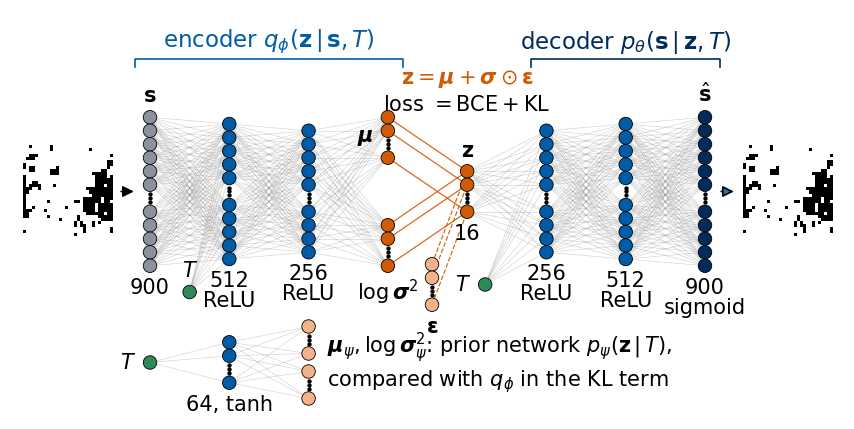

                                     CVAE Summary                                      
┏━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path       ┃ type   ┃ inputs           ┃ outputs         ┃ Param                    ┃
┡━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encode     │ CVAE   │ - float32[1,900] │ - float32[1,16] │ 1,201,476 (4.8 MB)       │
│            │        │ - float32[1,1]   │ - float32[1,16] │                          │
├────────────┼────────┼──────────────────┼─────────────────┼──────────────────────────┤
│ enc1       │ Linear │ float32[1,901]   │ float32[1,512]  │ bias: float32[512]       │
│            │        │                  │                 │ kernel: float32[901,512] │
│            │        │                  │                 │                          │
│            │        │                  │                 │ 461,824 (1.8 MB)         │
├────────────┼────────┼─────────

In [8]:
from matplotlib.patches import Circle
from matplotlib.collections import LineCollection

NODE_COLOR = {"input": "#8A929E", "hidden": "#005CA7", "latent": "#D35A05", "noise": "#F2B28A",
              "cond": "#2E8B57", "output": "#002B5C", "unused": "#E3E5E8"}


def draw_network(layers, edges, size=(5.5, 2.2), max_nodes=4, growth=0.9, gap=0.14, r=0.045, fontsize=10, notes=(),
                 fig=None):
    """Nodes-and-edges drawing of a network, created at its physical size (all coordinates in inches).

    layers   : dict name -> layer. A layer is a dict with
               x, y      position of the centre of the column (inches from the lower-left corner)
               n         true width of the layer (number of nodes)
               kind      colour key of NODE_COLOR: "input", "hidden", "latent", "noise", "cond", "output"
               top, bottom (optional) text written above / below the column; the true width n is
                         written below the column unless show_n=False
               left      (optional) text written left of the column
               shown     (optional) at most this many circles (keeps side columns such as mu, eps small)
               image     (optional) a 2D array drawn as a square picture instead of a column of nodes;
                         its side is given by `side` (inches)
    edges    : list of (a, b, style): lines from every drawn node of layer a to every drawn node of layer b
               ("dense": one line per weight), or from node j to node j only ("one": an element-wise
               operation, e.g. z = mu + sigma * eps), or "dashed": element-wise, dashed (random input),
               or "arrow": one arrow from the picture or column a to column b
    size     : figure size (inches); for a slide, 5.5 in wide = the full text width, so fonts are true sizes
    max_nodes, growth : a layer of width n <= max_nodes is drawn node by node; a wider layer gets
               max_nodes + growth * log2(n / max_nodes) circles and an ellipsis, so the height of a
               column grows with the width (784 nodes: 11 circles; 16 nodes: 6 circles)
    gap, r   : vertical distance between neighbouring circles and their radius (inches)
    fontsize : font size of all labels (points, as printed)
    notes    : extra texts, tuples (x, y, text, dict of matplotlib text options)
    fig      : draw into this figure (made by an earlier call) instead of a new one, e.g. two networks side by side
    Returns the figure.
    """
    if fig is None:                                            # one axes covering the figure, 1 data unit = 1 inch
        fig = plt.figure(figsize=size)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, size[0]); ax.set_ylim(0, size[1]); ax.set_aspect("equal"); ax.axis("off")
    ax = fig.axes[0]
    ys = {}                                                    # heights of the drawn nodes of every column

    # ---- the columns: circles (or a picture), an ellipsis for the omitted nodes, labels above and below
    for name, L in layers.items():
        x, y0 = L["x"], L["y"]
        if "image" in L:                                       # a picture, e.g. the input digit
            s = L.get("side", 0.55)
            ax.imshow(L["image"], cmap=L.get("cmap", "gray_r"), extent=(x - s / 2, x + s / 2, y0 - s / 2, y0 + s / 2),
                      interpolation="nearest", zorder=2)
            ys[name], half = np.array([y0]), s / 2
        else:
            n = L["n"]
            k = n if n <= max_nodes else max_nodes + int(round(growth * np.log2(n / max_nodes)))
            k = min(k, L.get("shown", k))                     # optional cap for small side columns
            capped = k < n
            slots = k + 1 if capped else k                     # one slot for the ellipsis if nodes are omitted
            y = y0 + gap * ((slots - 1) / 2 - np.arange(slots))
            if capped:                                         # three dots in the middle slot
                mid = slots // 2
                ax.scatter([x] * 3, y[mid] + gap * np.array([-0.28, 0, 0.28]), s=1.2, color="k", zorder=3)
                y = np.delete(y, mid)
            for yi in y:
                ax.add_patch(Circle((x, yi), r, facecolor=NODE_COLOR[L["kind"]], edgecolor="k", lw=0.4, zorder=3))
            ys[name], half = y, gap * (slots - 1) / 2 + r
        below = "\n".join(t for t in [str(L["n"]) if L.get("show_n", True) and "n" in L else "", L.get("bottom", "")] if t)
        if below:
            ax.text(x, y0 - half - 0.03, below, ha="center", va="top", fontsize=fontsize, linespacing=1.0)
        if L.get("left"):
            ax.text(x - r - 0.05, y0, L["left"], ha="right", va="center", fontsize=fontsize)
        if L.get("top"):
            ax.text(x, y0 + half + 0.03, L["top"], ha="center", va="bottom", fontsize=fontsize, linespacing=1.0)

    # ---- the edges: drawn below the circles, thin and semi-transparent, so that they end at the circles
    for a, b, style in edges:
        xa, xb = layers[a]["x"], layers[b]["x"]
        if style == "arrow":
            ax.annotate("", xy=(xb - 0.08, layers[b]["y"]), xytext=(xa + layers[a].get("side", 0) / 2 + 0.03, layers[a]["y"]),
                        arrowprops=dict(arrowstyle="-|>", lw=0.8, color="k"))
            continue
        if style == "dense":
            segs = [[(xa, p), (xb, q)] for p in ys[a] for q in ys[b]]
            kw = dict(colors="0.5", alpha=0.35, linewidths=0.3)
        else:                                                  # element-wise: node j -> node j
            segs = [[(xa, p), (xb, q)] for p, q in zip(ys[a], ys[b])]
            kw = dict(colors=NODE_COLOR["latent"], alpha=0.9, linewidths=0.6,
                      linestyles="--" if style == "dashed" else "-")
        ax.add_collection(LineCollection(segs, zorder=1, **kw))

    # ---- free texts: formulas, brackets naming encoder and decoder, ...
    for x, y, text, kw in notes:
        ax.text(x, y, text, fontsize=kw.pop("fontsize", fontsize), **kw)
    return fig


def bracket(ax, x0, x1, y, text, color="k", fontsize=10):
    """A horizontal bracket from x0 to x1 at height y (inches) with a text above it, naming a block of layers."""
    ax.plot([x0, x0, x1, x1], [y - 0.05, y, y, y - 0.05], color=color, lw=0.8)
    ax.text((x0 + x1) / 2, y + 0.03, text, ha="center", va="bottom", fontsize=fontsize, color=color)


def draw_ae(widths, d, x_img=None, xhat_img=None, size=(5.5, 1.95), fontsize=10):
    """Dense autoencoder: encoder widths [784, 256, 64] -> latent d -> mirrored decoder, with optional pictures."""
    cols = list(widths) + [d] + list(widths)[::-1]
    x0, x1 = 0.95, size[0] - 0.95                              # room for the two pictures
    xs = np.linspace(x0, x1, len(cols)); yc = 0.95
    m = len(widths)
    layers = {}
    for i, (n, x) in enumerate(zip(cols, xs)):
        kind = "input" if i == 0 else "output" if i == len(cols) - 1 else "latent" if i == m else "hidden"
        act = "" if i == 0 or i == m else "sigmoid" if i == len(cols) - 1 else "ReLU"
        top = r"$\mathbf{x}$" if i == 0 else r"$\hat{\mathbf{x}}$" if i == len(cols) - 1 else r"$\mathbf{z}$" if i == m else ""
        layers[f"l{i}"] = dict(x=x, y=yc, n=n, kind=kind, bottom=act, top=top)
    edges = [(f"l{i}", f"l{i + 1}", "dense") for i in range(len(cols) - 1)]
    if x_img is not None:
        layers["xin"] = dict(x=0.35, y=yc, image=np.asarray(x_img).reshape(28, 28), side=0.6)
        edges += [("xin", "l0", "arrow")]
    fig = draw_network(layers, edges, size=size, fontsize=fontsize, gap=0.11)
    ax = fig.axes[0]
    if xhat_img is not None:                                   # the reconstruction right of the output column
        ax.imshow(np.asarray(xhat_img).reshape(28, 28), cmap="gray_r", extent=(size[0] - 0.65, size[0] - 0.05, yc - 0.3, yc + 0.3))
        ax.annotate("", xy=(size[0] - 0.68, yc), xytext=(xs[-1] + 0.08, yc), arrowprops=dict(arrowstyle="-|>", lw=0.8))
    ytop = size[1] - 0.22
    bracket(ax, xs[0] - 0.1, xs[m] - 0.05, ytop, r"encoder $E$", color=NODE_COLOR["hidden"], fontsize=fontsize + 1)
    bracket(ax, xs[m] + 0.05, xs[-1] + 0.1, ytop, r"decoder $G$", color=NODE_COLOR["output"], fontsize=fontsize + 1)
    return fig


def draw_vae(enc, d, dec, cond=0, cond_name=r"$\mathbf{c}$", x_img=None, xhat_img=None, prior_net=None,
             x_name=r"\mathbf{x}", size=(5.5, 2.25), fontsize=10, gap=0.11, mode="train", region=None, compact=False,
             fig=None):
    """(Conditional) VAE drawn with nodes and edges.
    enc, dec  : widths of the encoder [784, 400, 200] and of the decoder [200, 400, 784]
    d         : latent dimension; the heads mu and log sigma^2 have d nodes each, z = mu + sigma * eps
                is element-wise (orange lines) and the noise eps is a separate input (dashed)
    cond      : number of condition inputs (0: plain VAE); the condition (green) enters the first layer
                of the encoder and of the decoder
    cond_name, x_name : symbols of the condition and of the data, e.g. "$T$" and r"\mathbf{s}" for spins
    x_img, xhat_img : optional pictures of an input and of its reconstruction at the two ends
    prior_net : hidden width of a prior network c -> (mu_psi, log sigma_psi^2), drawn in a lower row
    mode      : "train": encoder, sampling node and decoder, with the loss; "generate": only the decoder, fed by
                z ~ p(z) (and the chosen condition); the encoder is not used
    region    : (x_left, x_right) in inches: the part of the figure used by this drawing (default: all of it)
    compact   : leave out the activation names (for two drawings side by side)
    size, fontsize, gap : figure size (inches), font size (points) and node spacing (inches)
    fig       : draw into this existing figure"""
    W, H = size
    x_lo, x_hi = region if region is not None else (0.0, W)
    if compact:
        gap = min(gap, 0.1)
    yc = H - (1.33 if compact else 1.18)                       # height of the main row of columns
    ylow = yc - (0.7 if compact else 0.62)                     # row of the side inputs eps and c
    left = x_lo + (0.9 if x_img is not None else 0.3)
    right = x_hi - (0.9 if xhat_img is not None else 0.3)
    act = lambda name: "" if compact else name                 # activation names under the columns
    L, E = {}, []
    if mode == "train":
        xs = np.linspace(left, right, len(enc) + len(dec) + 2)     # columns: encoder, heads, z, decoder
        ex, hx, zx, dx = xs[:len(enc)], xs[len(enc)], xs[len(enc) + 1], xs[len(enc) + 2:]
        # ---- encoder: input column (raised if the condition sits under it) and hidden layers
        for i, (n, x) in enumerate(zip(enc, ex)):
            L[f"e{i}"] = dict(x=x, y=yc, n=n, kind="input" if i == 0 else "hidden",
                              bottom="" if i == 0 else act("ReLU"), top=rf"${x_name}$" if i == 0 else "")
            if i: E.append((f"e{i - 1}", f"e{i}", "dense"))
        # ---- the two heads, the noise and the sampled latent vector z = mu + sigma * eps
        L["mu"] = dict(x=hx, y=yc + 0.36, n=d, kind="latent", shown=3, show_n=False,
                       left=r"$\boldsymbol{\mu}$")
        L["lv"] = dict(x=hx, y=yc - 0.36, n=d, kind="latent", shown=3, show_n=False, bottom=r"$\log\boldsymbol{\sigma}^2$")
        L["eps"] = dict(x=zx - 0.12 if compact else (hx + zx) / 2 + 0.03, y=ylow, n=d, kind="noise", shown=3, show_n=False,
                        bottom=r"$\boldsymbol{\varepsilon}$")
        E += [(f"e{len(enc) - 1}", "mu", "dense"), (f"e{len(enc) - 1}", "lv", "dense"),
              ("mu", "z", "one"), ("lv", "z", "one"), ("eps", "z", "dashed")]
    else:
        xs = np.linspace(left, right, len(dec) + 2)                # columns: random source, z, decoder
        hx, zx, dx = xs[0], xs[1], xs[2:]
        L["src"] = dict(x=hx, y=yc, n=d, kind="noise", shown=3, show_n=False, bottom="random")
        E.append(("src", "z", "dashed"))
    L["z"] = dict(x=zx, y=yc, n=d, kind="latent", shown=3, top=r"$\mathbf{z}$", show_n=mode == "train")
    # ---- decoder
    for i, (n, x) in enumerate(zip(dec, dx)):
        last = i == len(dec) - 1
        L[f"d{i}"] = dict(x=x, y=yc, n=n, kind="output" if last else "hidden",
                          bottom=act("sigmoid") if last else act("ReLU"),
                          top=(rf"$\hat{{{x_name}}}$" if mode == "train" else rf"new ${x_name}$") if last else "")
        E.append(("z" if i == 0 else f"d{i - 1}", f"d{i}", "dense"))
    # ---- the condition, an input of the encoder (training only) and of the decoder
    if cond:
        x_ce = (ex[0] + ex[1]) / 2 if mode == "train" else 0     # between the input and the first hidden layer
        cd = [("cd", zx + 0.12, "d0")] + ([("ce", x_ce, "e1")] if mode == "train" else [])
        for key, x, to in cd:
            L[key] = dict(x=x, y=ylow - (0.05 if key == "ce" else 0), n=cond, kind="cond", shown=3,
                          show_n=cond > 1 and not compact, **{"top" if key == "ce" else "left": cond_name})
            E.append((key, to, "dense"))
    # ---- prior network p_psi(z | c), in a lower row under the encoder
    if prior_net and mode == "train":
        yp = 0.3
        L["cp"] = dict(x=ex[0], y=yp, n=cond, kind="cond", show_n=False, left=cond_name)
        L["ph"] = dict(x=ex[1], y=yp, n=prior_net, kind="hidden", shown=3, show_n=False, bottom=f"{prior_net}, tanh")
        L["pm"] = dict(x=ex[2], y=yp + 0.15, n=d, kind="noise", shown=2, show_n=False)
        L["pl"] = dict(x=ex[2], y=yp - 0.15, n=d, kind="noise", shown=2, show_n=False)
        E += [("cp", "ph", "dense"), ("ph", "pm", "dense"), ("ph", "pl", "dense")]
    if x_img is not None and mode == "train":
        L["xin"] = dict(x=x_lo + 0.35, y=L["e0"]["y"], image=x_img, side=0.6)
        E.append(("xin", "e0", "arrow"))
    fig = draw_network(L, E, size=size, fontsize=fontsize, gap=gap, fig=fig)
    ax = fig.axes[0]
    if xhat_img is not None:                                   # the reconstruction right of the output column
        ax.imshow(xhat_img, cmap="gray_r", extent=(x_hi - 0.65, x_hi - 0.05, yc - 0.3, yc + 0.3), interpolation="nearest")
        ax.annotate("", xy=(x_hi - 0.68, yc), xytext=(dx[-1] + 0.08, yc), arrowprops=dict(arrowstyle="-|>", lw=0.8))
    # ---- brackets naming the parts; sampling formula, loss or note on the unused encoder
    yb = H - (0.5 if compact else 0.3)
    cnd = ", " + cond_name.strip("$") if cond else ""
    enc_lab = r"encoder $q_\phi$" if compact else rf"encoder $q_\phi(\mathbf{{z}}\,|\,{x_name}{cnd})$"
    dec_lab = r"decoder $p_\theta$" if compact else rf"decoder $p_\theta({x_name}\,|\,\mathbf{{z}}{cnd})$"
    formula = r"$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\varepsilon}$"
    if mode == "train":
        bracket(ax, ex[0] - 0.1, hx + 0.1, yb, enc_lab, color=NODE_COLOR["hidden"], fontsize=fontsize + 1)
        ax.text((hx + dx[0]) / 2, yb - 0.13, formula, fontsize=fontsize, color=NODE_COLOR["latent"],
                ha="center", va="center")                      # sampling formula between the two brackets
        if not compact:                                        # the loss under the formula
            ax.text((hx + dx[0]) / 2, yb - 0.3, r"loss $= \mathrm{BCE} + \mathrm{KL}$", fontsize=fontsize,
                    ha="center", va="center")
    else:
        bracket(ax, hx - 0.15, zx + 0.1, yb, r"prior $\mathcal{N}(0, I)$", color=NODE_COLOR["latent"],
                fontsize=fontsize + 1)
        ax.text(x_lo + 0.02, 0.1, "encoder\nnot used", fontsize=fontsize, color=NODE_COLOR["input"],
                ha="left", va="bottom", style="italic", linespacing=1.0)
    bracket(ax, dx[0] - 0.1, dx[-1] + 0.1, yb, dec_lab, color=NODE_COLOR["output"], fontsize=fontsize + 1)
    if prior_net and mode == "train":
        ax.text(ex[2] + 0.12, 0.3, r"$\boldsymbol{\mu}_\psi, \log\boldsymbol{\sigma}^2_\psi$: prior network $p_\psi(\mathbf{z}\,|\,"
                + cond_name.strip("$") + r")$," + "\n" + r"compared with $q_\phi$ in the KL term", fontsize=fontsize,
                va="center", ha="left")
    return fig


def draw_vae_pair(enc, d, dec, cond=0, size=(5.5, 2.4), split=3.45, fontsize=10):
    """Training architecture (left) and generation architecture (right) of a (conditional) VAE in one figure.
    split: the x position (inches) where the generation drawing starts."""
    fig = draw_vae(enc, d, dec, cond=cond, mode="train", region=(0.0, split), compact=True, size=size, fontsize=fontsize)
    draw_vae(enc, d, dec, cond=cond, mode="generate", region=(split + 0.05, size[0]), compact=True, size=size,
             fontsize=fontsize, fig=fig)
    ax = fig.axes[0]
    ax.plot([split, split], [0.05, size[1] - 0.05], color="0.6", lw=0.8, ls=":")
    ax.text(split / 2, size[1] - 0.02, r"training: loss $= \mathrm{BCE} + \mathrm{KL}$", ha="center", va="top",
            fontsize=fontsize + 1, weight="bold")
    ax.text((split + size[0]) / 2, size[1] - 0.02, "generation", ha="center", va="top", fontsize=fontsize + 1, weight="bold")
    return fig


model_drawn = CVAE(N, 1, conditional_prior=True, rngs=nnx.Rngs(0))
with mpl.rc_context(SLIDE_RC):
    fig = draw_vae([N, 512, 256], 16, [256, 512, N], cond=1, cond_name="$T$", x_name=r"\mathbf{s}", prior_net=64,
                   x_img=S_train[i_c, 0], xhat_img=S_train[i_c, 0], size=(5.5, 2.62), gap=0.09)
    save(fig, "gen_l6_spin_arch.png"); plt.show()
table_kw = dict(depth=1, console_kwargs={"width": 110, "force_terminal": False, "force_jupyter": False})
print(nnx.tabulate(model_drawn, jnp.zeros((1, N)), jnp.zeros((1, 1)), method="encode", **table_kw))
print(nnx.tabulate(model_drawn, jnp.zeros((1, 1)), method="prior", **table_kw))

Before generating anything we monitor the health of the training. During training we record the training $-$ELBO per epoch and, every
5 epochs, the $-$ELBO on the held-out real data `S_A` + `S_B`. A held-out value that rises while the training value falls signals overfitting:
with 128 snapshots per temperature and $\sim1.2\times10^6$ parameters this starts after a few tens of epochs, so we train for 40 epochs.

After training we look at the KL per latent dimension on held-out data. A dimension with $\mathrm{KL}_j\approx0$ is ignored by the decoder
(an inactive unit); if all of them are inactive, the model has collapsed to $p(\mathbf s|c)$ without latent structure (posterior collapse).
We also report the fraction of spins that the decoder reproduces from $\mathbf z=\boldsymbol\mu(\mathbf s,c)$ with
$\hat s_i=\mathrm{sign}\,\ell_i$. For comparison, uniformly random spins would cost $N\log 2=623.8$ nats per configuration; the three variants
reach a held-out $-$ELBO between 387 and 392 nats, keep all 16 latent units active and reproduce about 80% of the spins.

In [9]:
def canonical(S):
    '''Z2 representative: flip every snapshot with m < 0 (the last two axes are the lattice).'''
    sign = np.where(S.sum(axis=(-1, -2), keepdims=True) >= 0, 1, -1).astype(np.int8)
    return S * sign

cond_I = lambda T: (np.asarray(T, np.float32) - 2.5)[..., None]       # (..., 1): the condition fed to the networks
S_test = np.concatenate([S_A, S_B], axis=1)                            # (37, 128, L, L) all held-out real data

@nnx.jit
def cvae_eval(model, x, c, key):
    '''Held-out terms: reconstruction (B,), KL per dimension (B, d), and the fraction of spins reproduced by sign(l) at z = mu.'''
    rec, kl = cvae_terms(model, x, c, key)
    mu, _ = model.encode(x, c)
    acc = (jnp.sign(model.decode(mu, c)) == x).mean(-1)
    return rec, kl, acc

def held_out_terms(model, X, C, key, batch=4096):
    '''cvae_eval in batches over X (n, N) int8 and C (n, n_cond); returns three concatenated numpy arrays.'''
    parts = [cvae_eval(model, jnp.asarray(X[i:i + batch], jnp.float32), jnp.asarray(C[i:i + batch]), jax.random.fold_in(key, i))
             for i in range(0, len(X), batch)]
    return [np.concatenate([np.asarray(p[j]) for p in parts]) for j in range(3)]

# name: (impose Z2, conditional prior, colour)
VARIANTS = {"cVAE": (False, False, orange), "cVAE+Z2": (True, False, green), "cVAE+Z2+p(z|T)": (True, True, blue)}
BEST = "cVAE+Z2+p(z|T)"
C_test = cond_I(np.repeat(T_grid, S_test.shape[1]))                    # (37*128, 1)

def fit_cvae(symmetric, conditional_prior, epochs=40, seed=0):
    '''Train a cVAE on S_train; monitor -ELBO on the held-out S_test. Returns model, training history, held-out curve.'''
    S_tr, S_ho = (canonical(S_train), canonical(S_test)) if symmetric else (S_train, S_test)
    X = S_tr.reshape(-1, N)                                            # int8 (37*128, N)
    C = cond_I(np.repeat(T_grid, S_tr.shape[1]))                       # (37*128, 1)
    model = CVAE(N, 1, conditional_prior=conditional_prior, rngs=nnx.Rngs(seed))
    curve = []
    def monitor(model, epoch):
        rec, kl, _ = held_out_terms(model, S_ho.reshape(-1, N), C_test, jax.random.key(99))
        curve.append((epoch, float((rec + kl.sum(-1)).mean())))
    hist = train_model(model, cvae_loss, (X, C), epochs=epochs, batch=128, lr=1e-3, seed=seed, callback=monitor, every=5)
    return model, hist, np.array(curve)

t0 = time.time()
models, histories, curves = {}, {}, {}
for name, (sym, cprior, _) in VARIANTS.items():
    models[name], histories[name], curves[name] = fit_cvae(sym, cprior)
    print(f"{name:15s}: trained in {time.time() - t0:3.0f} s;  -ELBO per configuration: training {histories[name][-1, 0]:.1f}, "
          f"held-out {curves[name][-1, 1]:.1f}   (uniform random spins: N log 2 = {N * np.log(2):.1f})")
    NUMBERS[f"ising_elbo_train_{name}"] = round(float(histories[name][-1, 0]), 1)
    NUMBERS[f"ising_elbo_test_{name}"] = round(float(curves[name][-1, 1]), 1)
NUMBERS["ising_cvae_train_seconds"] = round(time.time() - t0)

cVAE           : trained in  16 s;  -ELBO per configuration: training 367.8, held-out 391.3   (uniform random spins: N log 2 = 623.8)


cVAE+Z2        : trained in  31 s;  -ELBO per configuration: training 367.6, held-out 387.2   (uniform random spins: N log 2 = 623.8)


cVAE+Z2+p(z|T) : trained in  49 s;  -ELBO per configuration: training 363.2, held-out 388.1   (uniform random spins: N log 2 = 623.8)


cVAE           : held-out reconstruction 373.9 nats, KL 17.3 nats, spins reproduced at z = mu: 80.5%, active units (KL_j > 0.01): 16 of 16
cVAE+Z2        : held-out reconstruction 370.5 nats, KL 16.7 nats, spins reproduced at z = mu: 80.8%, active units (KL_j > 0.01): 16 of 16


cVAE+Z2+p(z|T) : held-out reconstruction 371.5 nats, KL 16.5 nats, spins reproduced at z = mu: 80.7%, active units (KL_j > 0.01): 16 of 16


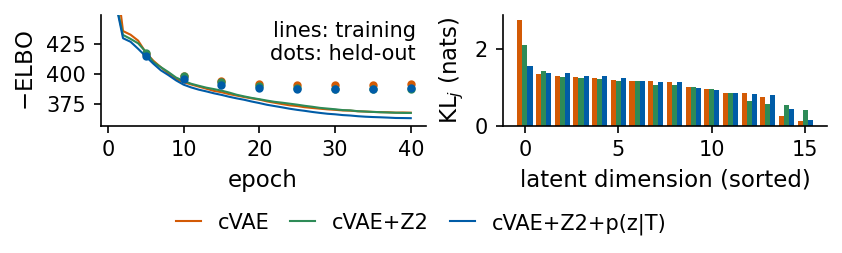

In [10]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(1, 2, figsize=(5.5, 1.6), layout="constrained")
    for k, (name, (sym, _, col)) in enumerate(VARIANTS.items()):
        ax[0].plot(np.arange(1, len(histories[name]) + 1), histories[name][:, 0], color=col, lw=1, label=name)
        ax[0].plot(curves[name][:, 0], curves[name][:, 1], "o", color=col, ms=3)
        S_ho = canonical(S_test) if sym else S_test
        rec, kl, acc = held_out_terms(models[name], S_ho.reshape(-1, N), C_test, jax.random.key(5))
        kl_dim = kl.mean(0)                                            # (d,) mean KL of each latent dimension
        active = int((kl_dim > 0.01).sum())
        ax[1].bar(np.arange(len(kl_dim)) + 0.27 * (k - 1), np.sort(kl_dim)[::-1], width=0.27, color=col)
        print(f"{name:15s}: held-out reconstruction {rec.mean():.1f} nats, KL {kl.sum(-1).mean():.1f} nats, "
              f"spins reproduced at z = mu: {100 * acc.mean():.1f}%, active units (KL_j > 0.01): {active} of {len(kl_dim)}")
        NUMBERS.update({f"ising_active_{name}": active, f"ising_recacc_{name}": round(float(acc.mean()), 3)})
    ax[0].set_ylim(top=1.15 * curves["cVAE"][:, 1].min())
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel(r"$-$ELBO")
    ax[0].text(0.97, 0.95, "lines: training\ndots: held-out", transform=ax[0].transAxes, ha="right", va="top", fontsize=10)
    ax[1].set_xlabel("latent dimension (sorted)"); ax[1].set_ylabel(r"$\mathrm{KL}_j$ (nats)")
    fig.legend(loc="outside lower center", ncol=3, handlelength=1.2, columnspacing=1.0)
    save(fig, "gen_l6_ising_training.png"); plt.show()

### 3.5 Synthetic data at the same conditions

With the three generators trained, each of them produces 64 configurations at every one of the 37 temperatures, the same number as in `S_A`
and `S_B`, using Bernoulli sampling. For the best model we also keep the most likely configuration $\hat s_i=\mathrm{sign}\,\ell_i$ obtained
from the same latent vectors, to see what happens when the sampling noise of the decoder is removed. The figure compares snapshots of all sets
side by side.

{'cVAE': (37, 64, 30, 30), 'cVAE+Z2': (37, 64, 30, 30), 'cVAE+Z2+p(z|T)': (37, 64, 30, 30), 'cVAE+Z2+p(z|T) (most likely)': (37, 64, 30, 30)}


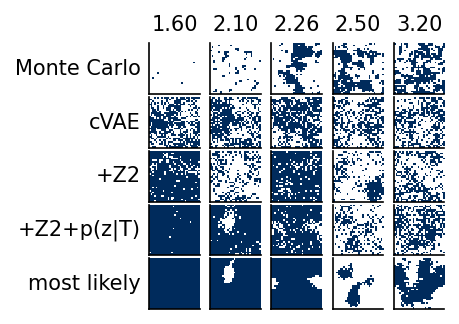

In [11]:
@nnx.jit
def decoder_logits(model, z, c):
    return model.decode(z, c)

def generate(model, cond, n_per_cond, key, side, symmetric=False, batch=8192):
    '''n_per_cond configurations at every condition row of cond (K, n_cond); z ~ p(z|c).
    Returns two int8 arrays (K, n_per_cond, side, side): Bernoulli samples and most likely configurations (same z).'''
    c_all = np.repeat(np.asarray(cond, np.float32), n_per_cond, axis=0)          # (K * n, n_cond)
    bern, ml = [], []
    for i in range(0, len(c_all), batch):
        k_z, k_s, k_f = jax.random.split(jax.random.fold_in(key, i), 3)
        c = jnp.asarray(c_all[i:i + batch])
        mu_p, logvar_p = model.prior(c)                                          # (b, d) each; zeros for N(0, 1)
        z = mu_p + jnp.exp(0.5 * logvar_p) * jax.random.normal(k_z, mu_p.shape)  # z ~ p(z|c)
        logits = decoder_logits(model, z, c)                                     # (b, side*side)
        s_b = jnp.where(jax.random.bernoulli(k_s, jax.nn.sigmoid(logits)), 1, -1)   # independent Bernoulli spins
        s_m = jnp.where(logits > 0, 1, -1)                                        # most likely configuration
        if symmetric:                                                             # global flip with probability 1/2
            flip = jnp.where(jax.random.bernoulli(k_f, 0.5, (len(c), 1)), -1, 1)
            s_b, s_m = s_b * flip, s_m * flip
        bern.append(np.asarray(s_b, np.int8)); ml.append(np.asarray(s_m, np.int8))
    shape = (len(cond), n_per_cond, side, side)
    return np.concatenate(bern).reshape(shape), np.concatenate(ml).reshape(shape)

ML = BEST + " (most likely)"
SYN = {}                                                                         # name -> (37, 64, L, L) int8
for k, (name, (sym, _, _)) in enumerate(VARIANTS.items()):
    SYN[name], s_ml = generate(models[name], cond_I(T_grid), 64, jax.random.key(10 + k), L, sym)
    if name == BEST:
        SYN[ML] = s_ml
print({k: v.shape for k, v in SYN.items()})

T_show = [1.6, 2.1, T_grid[i_c], 2.5, 3.2]
rows = [("Monte Carlo", S_A)] + [(n.replace("cVAE+", "+"), SYN[n]) for n in VARIANTS] + [("most likely", SYN[ML])]
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(len(rows), len(T_show), figsize=(2.6, 2.3), gridspec_kw=dict(wspace=0.06, hspace=0.06))
    for k, Tv in enumerate(T_show):
        i = int(np.argmin(np.abs(T_grid - Tv)))
        for r, (nm, S) in enumerate(rows):
            ax[r, k].imshow(S[i, 1], cmap=SPIN, vmin=-1, vmax=1, interpolation="nearest")
            ax[r, k].set_xticks([]); ax[r, k].set_yticks([])
            if k == 0: ax[r, k].set_ylabel(nm, fontsize=10, rotation=0, ha="right", va="center")
        ax[0, k].set_title(f"{T_grid[i]:.2f}", fontsize=10)
    save(fig, "gen_l6_ising_samples.png"); plt.show()

### 3.6 Spin sampling and Monte Carlo

Before testing the synthetic data statistically we look at how a single synthetic configuration comes about, for the best model at two temperatures, $T=1.8$ (ordered) and $T=2.26$ (near $T_c$). Each row of the next figure starts with a Monte Carlo snapshot from `S_A` for comparison. Then comes the decoder output for one latent vector $\mathbf z\sim p_\psi(\mathbf z|T)$: the probability $\sigma(\ell_i)$ that each spin points up, as a grey level (white 0, navy 1). The next two panels are two independent Bernoulli samples from these same probabilities, and the last panel is the most likely configuration $\mathrm{sign}\,\ell_i$.

The figure is followed by a quantitative check of the mean-field structure. For the synthetic snapshots we compare the nearest-neighbour correlation $G(1)$ measured on the Bernoulli samples with the value predicted from the probabilities alone, assuming independent spins, $\frac1{2N}\sum_{\mathbf x,\mu}\overline{\tanh(\ell_{\mathbf x}/2)\tanh(\ell_{\mathbf x+\hat e_\mu}/2)}$, the average over the latent vectors of the products of the mean spins. If the spins are indeed independent given $\mathbf z$, the two agree; the Monte Carlo value of $G(1)=-\langle e\rangle/2$ is printed next to them.

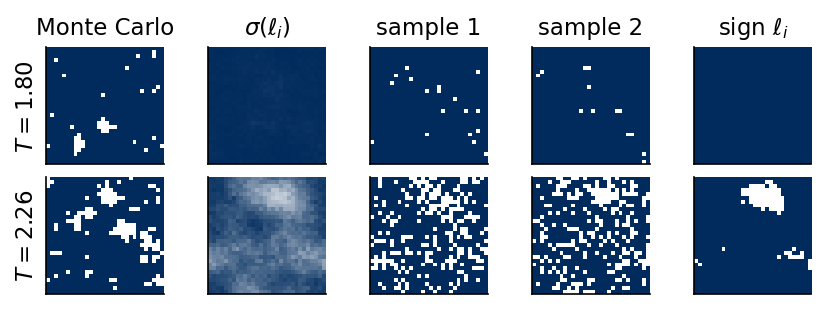

T = 1.80:  G(1) of Bernoulli samples 0.894,  independent-spin prediction 0.895,  Monte Carlo 0.930
T = 2.26:  G(1) of Bernoulli samples 0.520,  independent-spin prediction 0.521,  Monte Carlo 0.717


In [12]:
@nnx.jit
def logits_at(model, z, c):
    return model.decode(z, c)

def mean_field_G1(model, T, n, key):
    """G(1) of Bernoulli samples and its independent-spin prediction, both from the same n latent vectors at T."""
    c = jnp.asarray(cond_I(np.full(n, T)))
    mu_p, lv_p = model.prior(c)
    z = mu_p + jnp.exp(0.5 * lv_p) * jax.random.normal(key, mu_p.shape)
    l = np.asarray(logits_at(model, z, c)).reshape(n, L, L)
    m = np.tanh(l / 2)                                                        # <s_i> given z
    s = np.where(np.random.default_rng(5).random(l.shape) < 1 / (1 + np.exp(-l)), 1.0, -1.0)
    nn = lambda a, b: 0.5 * ((a * np.roll(b, 1, -1)).mean() + (a * np.roll(b, 1, -2)).mean())
    return nn(s, s), nn(m, m), l

rows_T = [1.8, 2.26]
mf = {}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(2, 5, figsize=(5.5, 1.95), layout="constrained")
    for r, Tv in enumerate(rows_T):
        i = int(np.argmin(np.abs(T_grid - Tv)))
        G_s, G_m, l = mean_field_G1(models[BEST], T_grid[i], 256, jax.random.key(70 + r))
        mf[float(T_grid[i])] = (G_s, G_m, float(P_A["G"][i, 1]))
        p_up = 1 / (1 + np.exp(-l[0]))
        rng_s = np.random.default_rng(80 + r)
        panels = [(S_A[i, 0], "Monte Carlo"), (p_up, r"$\sigma(\ell_i)$"),
                  (np.where(rng_s.random(p_up.shape) < p_up, 1, -1), "sample 1"),
                  (np.where(rng_s.random(p_up.shape) < p_up, 1, -1), "sample 2"), (np.where(l[0] > 0, 1, -1), r"sign $\ell_i$")]
        for k, (img, title) in enumerate(panels):
            if k == 1:
                ax[r, k].imshow(img, cmap=SPIN_GREY, vmin=0, vmax=1, interpolation="nearest")
            else:
                ax[r, k].imshow(img, cmap=SPIN, vmin=-1, vmax=1, interpolation="nearest")
            ax[r, k].set_xticks([]); ax[r, k].set_yticks([])
            if r == 0: ax[r, k].set_title(title, fontsize=11)
        ax[r, 0].set_ylabel(f"$T={T_grid[i]:.2f}$", fontsize=11)
    save(fig, "gen_l6_spin_sampling.png"); plt.show()
for Tv, (G_s, G_m, G_mc) in mf.items():
    print(f"T = {Tv:.2f}:  G(1) of Bernoulli samples {G_s:.3f},  independent-spin prediction {G_m:.3f},  Monte Carlo {G_mc:.3f}")
NUMBERS["mf_G1"] = {f"{Tv:.2f}": [round(float(v), 3) for v in vals] for Tv, vals in mf.items()}

The decoder output is a smooth map of probabilities: inside a domain the probabilities are close to 0 or 1, at the domain walls and in the disordered regions they are intermediate. A Bernoulli sample turns every intermediate probability into an independent coin flip, which produces the salt-and-pepper noise inside the domains, and two samples from the same $\mathbf z$ share the large-scale pattern but differ spin by spin. The most likely configuration removes the noise and keeps only the smooth domains. Neither looks like the Monte Carlo snapshot at short distances, where neighbouring spins are correlated through the bonds of $H$.

The printed correlations confirm the mean-field structure: the nearest-neighbour correlation of the Bernoulli samples equals the prediction from the product of the mean spins, up to sampling noise, so the generated spins are independent given $\mathbf z$, exactly as the decoder prescribes. Both numbers lie below the Monte Carlo $G(1)$ at the same temperature: the generator has fewer satisfied bonds, hence a higher energy, than the Boltzmann distribution. The order parameter, by contrast, is a sum over all spins, and the independent coin flips average out in it. This is the mechanism behind every result of the following sections.

### 3.7 Evaluation by networks trained on real simulations

We now apply the regressor and the classifier of Section 3.3 to `S_A`, `S_B` and to the synthetic sets. A synthetic snapshot "looks like
temperature $T$" to the regressor if $\hat T\approx T$, and the minimum of the classifier's confidence marks the transition it sees. In the
output, the real sets give an RMSE of 0.12 and a confidence minimum at $T=2.28$. The plain cVAE reads as far too hot at low temperature
(mean $\hat T=2.77$ at $T=1.5$) and puts the confidence minimum at $T=1.7$. The conditional prior brings the low-temperature end back
($\hat T=1.69$ at $T=1.5$) and the confidence minimum to $T=2.2$, yet the RMSE of 0.62 is still five times that of real data, while the most
likely configurations are read as far too cold.

Monte Carlo A                  regressor RMSE 0.120   mean T_hat at T = 1.5 / 2.26 / 3.5: 1.61 / 2.27 / 3.29   confidence minimum at T = 2.28
Monte Carlo B                  regressor RMSE 0.116   mean T_hat at T = 1.5 / 2.26 / 3.5: 1.61 / 2.28 / 3.30   confidence minimum at T = 2.28
cVAE                           regressor RMSE 0.978   mean T_hat at T = 1.5 / 2.26 / 3.5: 2.77 / 3.13 / 3.77   confidence minimum at T = 1.7
cVAE+Z2                        regressor RMSE 0.837   mean T_hat at T = 1.5 / 2.26 / 3.5: 2.34 / 3.04 / 3.78   confidence minimum at T = 2.22
cVAE+Z2+p(z|T)                 regressor RMSE 0.623   mean T_hat at T = 1.5 / 2.26 / 3.5: 1.69 / 2.79 / 3.73   confidence minimum at T = 2.2
cVAE+Z2+p(z|T) (most likely)   regressor RMSE 0.715   mean T_hat at T = 1.5 / 2.26 / 3.5: 1.51 / 1.68 / 2.15   confidence minimum at T = 2.6


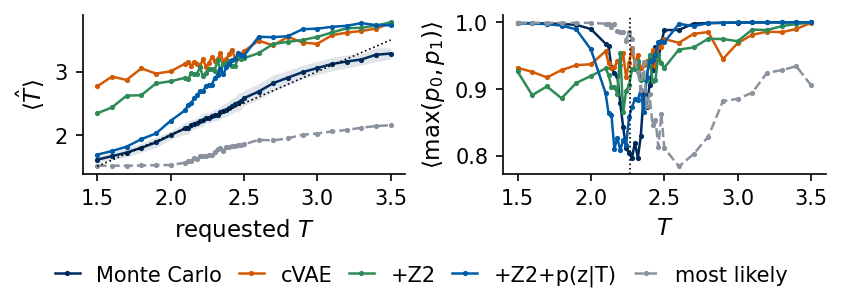

In [13]:
EVAL = {"Monte Carlo A": (That_A, p1_A), "Monte Carlo B": (That_B, p1_B)}
for name in SYN:
    EVAL[name] = evaluate(SYN[name])
for name, (Th, p1) in EVAL.items():
    print(f"{name:30s} regressor RMSE {rmse(Th):.3f}   mean T_hat at T = 1.5 / {T_grid[i_c]} / 3.5: "
          f"{Th[0].mean():.2f} / {Th[i_c].mean():.2f} / {Th[-1].mean():.2f}   confidence minimum at T = {T_grid[np.argmin(confidence(p1))]}")
    NUMBERS[f"ising_rmse_{name}"] = round(rmse(Th), 3)
    NUMBERS[f"ising_confmin_{name}"] = float(T_grid[np.argmin(confidence(p1))])

styles = [("Monte Carlo A", navy, "-")] + [(n, VARIANTS[n][2], "-") for n in VARIANTS] + [(ML, grey, "--")]
SHORT = {"Monte Carlo A": "Monte Carlo", "cVAE": "cVAE", "cVAE+Z2": "+Z2", "cVAE+Z2+p(z|T)": "+Z2+p(z|T)", ML: "most likely"}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(1, 2, figsize=(5.5, 1.95), layout="constrained")
    for name, col, ls in styles:
        Th, p1 = EVAL[name]
        ax[0].plot(T_grid, Th.mean(1), ls, color=col, marker=".", ms=3, lw=1.2, label=SHORT[name])
        ax[1].plot(T_grid, confidence(p1), ls, color=col, marker=".", ms=3, lw=1.2)
    Th_A = EVAL["Monte Carlo A"][0]
    ax[0].fill_between(T_grid, Th_A.mean(1) - Th_A.std(1), Th_A.mean(1) + Th_A.std(1), color=navy, alpha=0.12, lw=0)
    ax[0].plot(T_grid, T_grid, ":", color="k", lw=0.8)
    ax[0].set_xlabel("requested $T$"); ax[0].set_ylabel(r"$\langle\hat T\rangle$")
    ax[1].axvline(TC, color="k", ls=":", lw=0.8)
    ax[1].set_xlabel("$T$"); ax[1].set_ylabel(r"$\langle\max(p_0,p_1)\rangle$")
    fig.legend(loc="outside lower center", ncol=5, handlelength=1.2, columnspacing=0.8)
    save(fig, "gen_l6_ising_evaluators.png"); plt.show()

### 3.8 Hamiltonian observables of the synthetic data

The second family of tests uses the Hamiltonian. We compute all observables of Section 3.2 for `S_A`, `S_B` and the synthetic sets; in the
figure the shaded band is the real-vs-real spread between `S_A` and `S_B`, and the table below it gives the noise ratios $R$ together with the
values of $\langle e\rangle$, $\langle|m|\rangle$ and $c$ at a few temperatures. Look first at the column for the energy: even the best
model, cVAE+Z2+p(z|T), is 34.8 noise units away from the Monte Carlo energy, while its magnetisation is within 2.8 noise units.

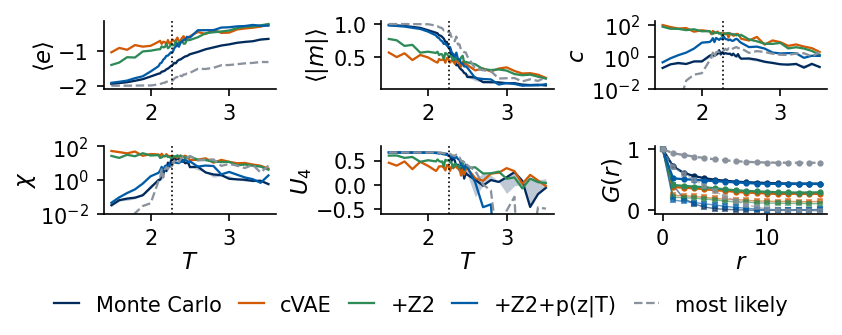

noise units R = mean_T|O_syn - O_A| / mean_T|O_B - O_A|   (R ~ 1: as close as an independent Monte Carlo set)
                                     e       m       c     chi      U4   W1(e)   W1(m)  G(L/2)
Monte Carlo B                      1.0     1.0     1.0     1.0     1.0     1.0     1.0     1.0
cVAE                              60.0    13.3   155.4    11.8     2.1    38.1     3.3    15.0
cVAE+Z2                           50.0    10.8   146.1     9.7     1.7    31.9     2.8    12.4
cVAE+Z2+p(z|T)                    34.8     2.8    39.0     2.0     4.2    21.6     1.3     3.0
cVAE+Z2+p(z|T) (most likely)      39.6     9.6     6.6     3.7     3.2    24.5     2.8    11.1

T                              [1.5  2.   2.26 2.5  3.   3.5 ]
<e> Monte Carlo A            [-1.953 -1.737 -1.433 -1.1   -0.819 -0.663]
<e> Monte Carlo B            [-1.952 -1.737 -1.439 -1.122 -0.819 -0.655]
<e> cVAE                     [-1.045 -0.86  -0.757 -0.587 -0.483 -0.247]
<e> cVAE+Z2                  [-1.407 

In [14]:
PHYS = {"Monte Carlo A": P_A, "Monte Carlo B": P_B}
for name in SYN:
    PHYS[name] = ising_observables(SYN[name], T_grid)

labels = {"e": r"$\langle e\rangle$", "m": r"$\langle|m|\rangle$", "c": r"$c$", "chi": r"$\chi$", "U4": r"$U_4$"}
i_hot = int(np.argmin(np.abs(T_grid - 3.0)))
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(2, 3, figsize=(5.5, 2.15), layout="constrained")
    for a, key in zip(ax.ravel()[:5], labels):
        a.fill_between(T_grid, np.minimum(P_A[key], P_B[key]), np.maximum(P_A[key], P_B[key]), color=navy, alpha=0.25, lw=0)
        for name, col, ls in styles:
            a.plot(T_grid, PHYS[name][key], ls, color=col, lw=1.1, label=SHORT[name])
        a.axvline(TC, color="k", ls=":", lw=0.8); a.set_ylabel(labels[key], labelpad=1)
        if key in ("c", "chi"): a.set_yscale("log"); a.set_ylim(bottom=1e-2)
        if key == "U4": a.set_ylim(-0.6, 0.8)                         # U4 = 1 - <m^4>/3<m^2>^2 is noisy where <m^2> ~ 1/N
    for a in ax[1]: a.set_xlabel("$T$", labelpad=1)
    a = ax[1, 2]
    for name, col, ls in styles:
        a.plot(PHYS[name]["G"][i_c], ls, color=col, marker="o", ms=2, lw=1.1)
        a.plot(PHYS[name]["G"][i_hot], ls, color=col, marker="s", ms=2, lw=0.7, alpha=0.6)
    a.set_xlabel("$r$", labelpad=1); a.set_ylabel("$G(r)$", labelpad=1)
    fig.legend(*ax[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=5, handlelength=1.2, columnspacing=0.8)
    save(fig, "gen_l6_ising_physics.png"); plt.show()

print("noise units R = mean_T|O_syn - O_A| / mean_T|O_B - O_A|   (R ~ 1: as close as an independent Monte Carlo set)")
# G(1) = -<e>/2 for the Ising model (both are the nearest-neighbour correlation), so we test the long-distance value G(L/2) instead
print(f"{'':30s}" + "".join(f"{k:>8s}" for k in list(labels) + ["W1(e)", "W1(m)", "G(L/2)"]))
W1 = {"Monte Carlo B": (W_AB_e, W_AB_m)}
for name in ["Monte Carlo B"] + list(SYN):
    P = PHYS[name]
    W1[name] = (wasserstein1(P["e_samples"], P_A["e_samples"]), wasserstein1(P["m_samples"], P_A["m_samples"]))
    R = [noise_ratio(P[k], P_A[k], P_B[k]) for k in labels]
    R += [noise_ratio(W1[name][0], 0, W_AB_e), noise_ratio(W1[name][1], 0, W_AB_m), noise_ratio(P["G"][:, -1], P_A["G"][:, -1], P_B["G"][:, -1])]
    print(f"{name:30s}" + "".join(f"{r:8.1f}" for r in R))
    NUMBERS[f"ising_R_{name}"] = dict(zip(list(labels) + ["W1e", "W1m", "GL2"], [round(r, 1) for r in R]))
sel = [0, int(np.argmin(np.abs(T_grid - 2.0))), i_c, int(np.argmin(np.abs(T_grid - 2.5))), i_hot, n_T - 1]
print(f"\nT                              {np.round(T_grid[sel], 2)}")
for key in ["e", "m", "c"]:
    for name in ["Monte Carlo A", "Monte Carlo B"] + list(SYN):
        print(f"<{key}> {name:24s} {np.round(PHYS[name][key][sel], 3)}")
    NUMBERS[f"ising_{key}_table"] = {"T": [float(t) for t in T_grid[sel]],
                                     **{n: [round(float(v), 3) for v in PHYS[n][key][sel]] for n in ["Monte Carlo A", BEST, ML]}}

Agreement of averages does not imply agreement of distributions, so we compare the full distributions as well. We compute $W_1$
between the synthetic and the real `S_A` distributions of $e$ and $m$ at every temperature, against the real-vs-real value $W_1(A,B)$, and
show the histograms of $P(e)$ and $P(m)$ at three temperatures. Below $T_c$ we also count the snapshots whose $|m|$ is less than half the Monte
Carlo value: these are mixtures of the two ordered states. In the Monte Carlo data their fraction is 0.011, for the plain cVAE it is 0.450,
with the $\mathbb Z_2$ symmetry it drops to 0.271, and with the conditional prior to 0.009.

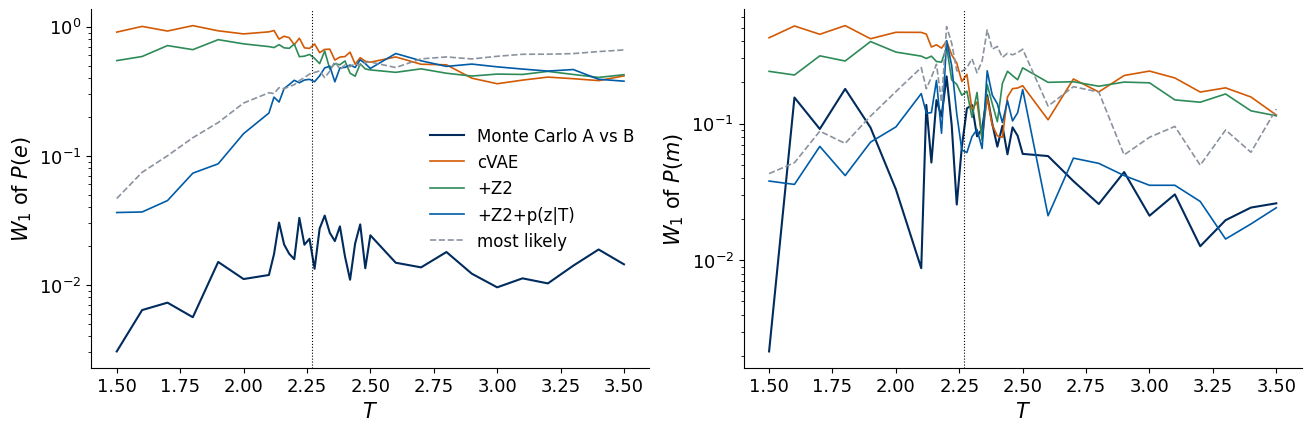

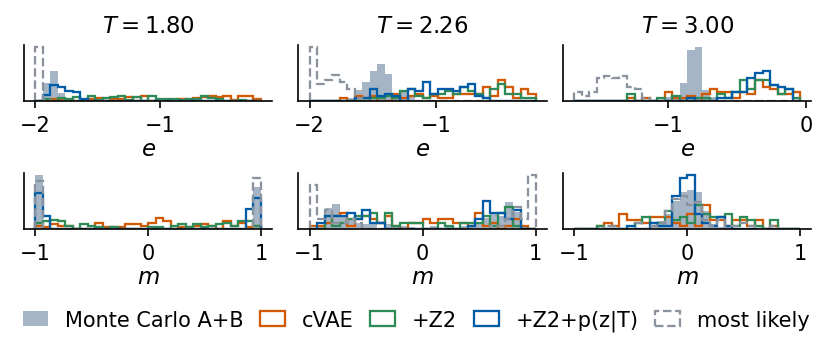

Monte Carlo A   T < T_c: fraction with m > 0: 0.515;  fraction with |m| < <|m|>_MC / 2 (mixtures of the two ordered states): 0.011
cVAE            T < T_c: fraction with m > 0: 0.500;  fraction with |m| < <|m|>_MC / 2 (mixtures of the two ordered states): 0.450
cVAE+Z2         T < T_c: fraction with m > 0: 0.506;  fraction with |m| < <|m|>_MC / 2 (mixtures of the two ordered states): 0.271
cVAE+Z2+p(z|T)  T < T_c: fraction with m > 0: 0.477;  fraction with |m| < <|m|>_MC / 2 (mixtures of the two ordered states): 0.009


In [15]:
T3 = [int(np.argmin(np.abs(T_grid - t))) for t in (1.8, TC, 3.0)]
# notebook figure: W1 distance to Monte Carlo A as a function of T
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
for row, (key, xl) in enumerate([("e_samples", "$e$"), ("m_samples", "$m$")]):
    a = axs[row]
    a.plot(T_grid, W1["Monte Carlo B"][row], color=navy, lw=1.5, label="Monte Carlo A vs B")
    for name, col, ls in styles[1:]:
        a.plot(T_grid, W1[name][row], ls, color=col, lw=1.2, label=SHORT[name])
    a.set_yscale("log"); a.axvline(TC, color="k", ls=":", lw=0.8)
    a.set_xlabel("$T$"); a.set_ylabel(f"$W_1$ of $P$({xl})")
axs[0].legend(); plt.show()

# slide figure: P(e) and P(m) at three temperatures
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(2, 3, figsize=(5.5, 2.25), layout="constrained")
    for row, (key, xl) in enumerate([("e_samples", "$e$"), ("m_samples", "$m$")]):
        for k, i in enumerate(T3):
            a = ax[row, k]
            allv = np.concatenate([PHYS[n][key][i] for n, _, _ in styles])
            bins = np.linspace(-1, 1, 31) if key == "m_samples" else np.linspace(allv.min(), allv.max(), 31)
            a.hist(np.concatenate([P_A[key][i], P_B[key][i]]), bins, density=True, color=navy, alpha=0.35,
                   label="Monte Carlo A+B")
            for name, col, ls in styles[1:]:
                a.hist(PHYS[name][key][i], bins, density=True, histtype="step", color=col, lw=1.1, ls=ls, label=SHORT[name])
            a.set_xlabel(xl, labelpad=1); a.set_yticks([])
            if row == 0: a.set_title(f"$T={T_grid[i]:.2f}$")
    fig.legend(*ax[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=5, handlelength=1.2, columnspacing=0.8)
    save(fig, "gen_l6_ising_distributions.png"); plt.show()

below = T_grid < TC
for name, S in [("Monte Carlo A", S_A)] + [(n, SYN[n]) for n in VARIANTS]:
    m = S.astype(np.float32).mean((-1, -2))[below]                   # (n_T below T_c, 64)
    frac_mid = float((np.abs(m) < 0.5 * np.abs(P_A["m_samples"][below]).mean(1, keepdims=True)).mean())
    print(f"{name:15s} T < T_c: fraction with m > 0: {(m > 0).mean():.3f};  "
          f"fraction with |m| < <|m|>_MC / 2 (mixtures of the two ordered states): {frac_mid:.3f}")
    NUMBERS[f"ising_mpos_{name}"] = round(float((m > 0).mean()), 3); NUMBERS[f"ising_mixed_{name}"] = round(frac_mid, 3)

### 3.9 Two-sample test and memorisation

The physics tests check selected observables; a classifier two-sample test (C2ST) checks the distribution as a whole. If two sets come from
the same distribution, no classifier can tell them apart better than chance. At three temperatures we train a fresh small CNN to separate real
from synthetic snapshots (balanced classes, 75% for training, 25% held out) and report the held-out accuracy: 0.5 means indistinguishable,
1.0 means trivially separable. As a sanity check, real (`S_train`) against real (`S_A`+`S_B`) must give $\approx0.5$.

A generator that copies its training set would pass every physics test, so we must also exclude memorisation. For every synthetic and every
held-out real snapshot we compute the normalised Hamming distance to the nearest training snapshot at the same $T$, minimised over the global
flip:
$$
d_{\rm NN}(\mathbf s)=\min_{\mathbf t\in\text{train}}\ \frac{1-|\mathbf s\cdot\mathbf t|/N}{2}\in[0,\tfrac12].
$$
Real held-out snapshots are new draws from the Boltzmann distribution, so their $d_{\rm NN}$ is the reference; a synthetic $d_{\rm NN}$ much
smaller than the real one would mean copying.

C2ST held-out accuracy (0.5 = indistinguishable), 78 s
  real vs real                     T = 1.80: 0.50 (n_test = 64)   T = 2.26: 0.53 (n_test = 64)   T = 3.00: 0.50 (n_test = 64)
  cVAE                             T = 1.80: 0.95 (n_test = 128)   T = 2.26: 0.94 (n_test = 128)   T = 3.00: 0.99 (n_test = 128)
  cVAE+Z2                          T = 1.80: 0.95 (n_test = 128)   T = 2.26: 0.98 (n_test = 128)   T = 3.00: 1.00 (n_test = 128)
  cVAE+Z2+p(z|T)                   T = 1.80: 0.73 (n_test = 128)   T = 2.26: 0.95 (n_test = 128)   T = 3.00: 0.98 (n_test = 128)
  cVAE+Z2+p(z|T) (most likely)     T = 1.80: 1.00 (n_test = 128)   T = 2.26: 0.98 (n_test = 128)   T = 3.00: 0.99 (n_test = 128)
nearest-neighbour distance to the training set, median at T = 1.80: 0.027, 2.26: 0.182, 3.00: 0.427;  minimum over all T 0.003   [Monte Carlo A]
nearest-neighbour distance to the training set, median at T = 1.80: 0.276, 2.26: 0.270, 3.00: 0.414;  minimum over all T 0.003   [cVAE]
nearest-neighbour dist

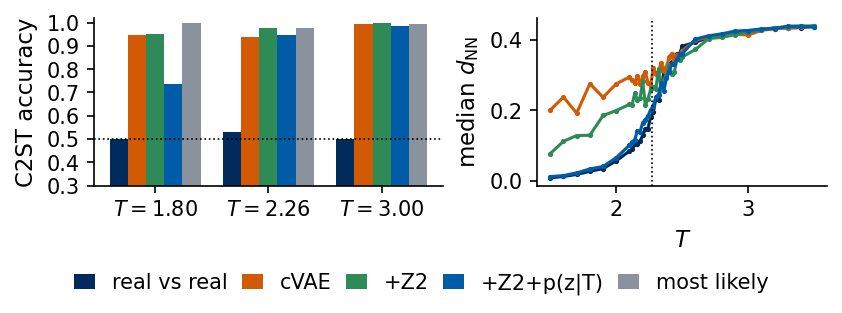

In [16]:
def c2st(X1, X2, seed, epochs=25):
    '''Held-out accuracy of a CNN trained to separate X1 (n1, L, L) from X2 (n2, L, L).
    Both classes are cut to n = min(n1, n2) and split 75 / 25 *within each class* (stratified): with a plain random split a
    class that is over-represented in training is under-represented in the test set, which biases the accuracy below 0.5.'''
    n = min(len(X1), len(X2)); n_tr = int(0.75 * n)
    r = np.random.default_rng(seed)
    p1, p2 = r.permutation(len(X1))[:n], r.permutation(len(X2))[:n]
    X_tr = np.concatenate([X1[p1[:n_tr]], X2[p2[:n_tr]]]); y_tr = np.repeat(np.array([0, 1], np.int32), n_tr)
    X_te = np.concatenate([X1[p1[n_tr:]], X2[p2[n_tr:]]]); y_te = np.repeat(np.array([0, 1], np.int32), n - n_tr)
    model = CNN(2, rngs=nnx.Rngs(seed))
    train_model(model, xent_loss, (X_tr, y_tr), epochs=epochs, batch=32, lr=3e-3, seed=seed)
    pred = predict(model, X_te).argmax(-1)
    return float((pred == y_te).mean()), len(y_te)

t0 = time.time()
C2ST = {}
c2st_names = ["real vs real"] + list(VARIANTS) + [ML]
for i in T3:
    real_all = np.concatenate([S_train[i], S_A[i], S_B[i]])                       # (256, L, L)
    C2ST[("real vs real", i)] = c2st(S_train[i], np.concatenate([S_A[i], S_B[i]]), seed=i)
    for k, (name, (sym, _, _)) in enumerate(VARIANTS.items()):
        syn, syn_ml = generate(models[name], cond_I(T_grid[[i]]), 256, jax.random.key(100 + 10 * i + k), L, sym)
        C2ST[(name, i)] = c2st(real_all, syn[0], seed=i)
        if name == BEST:
            C2ST[(ML, i)] = c2st(real_all, syn_ml[0], seed=i)
print(f"C2ST held-out accuracy (0.5 = indistinguishable), {time.time() - t0:.0f} s")
for name in c2st_names:
    accs = [C2ST[(name, i)][0] for i in T3]
    print(f"  {name:30s}" + "".join(f"   T = {T_grid[i]:.2f}: {a:.2f} (n_test = {C2ST[(name, i)][1]})" for a, i in zip(accs, T3)))
    NUMBERS[f"ising_c2st_{name}"] = [round(a, 2) for a in accs]

def nn_hamming(Q, R):
    '''Q (nq, L, L), R (nr, L, L) spins -> (nq,) normalised Hamming distance to the nearest R, minimised over the global flip.'''
    q = Q.reshape(len(Q), -1).astype(np.float32); r = R.reshape(len(R), -1).astype(np.float32)
    overlap = q @ r.T / q.shape[1]                                     # (nq, nr) in [-1, 1]
    return ((1.0 - np.abs(overlap)) / 2.0).min(axis=1)                 # |overlap|: the flipped copy counts as the same

D_NN = {name: np.stack([nn_hamming(S[i], S_train[i]) for i in range(n_T)])
        for name, S in [("Monte Carlo A", S_A)] + [(n, SYN[n]) for n in VARIANTS]}   # (37, 64) each
for name, d in D_NN.items():
    print(f"nearest-neighbour distance to the training set, median at T = " +
          ", ".join(f"{T_grid[i]:.2f}: {np.median(d[i]):.3f}" for i in T3) + f";  minimum over all T {d.min():.3f}   [{name}]")
    NUMBERS[f"ising_dnn_{name}"] = [round(float(np.median(d[i])), 3) for i in T3]

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(1, 2, figsize=(5.5, 2.0), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1]})
    cols = [navy] + [VARIANTS[n][2] for n in VARIANTS] + [grey]
    w = 0.16
    for k, (name, col) in enumerate(zip(c2st_names, cols)):
        ax[0].bar(np.arange(3) + (k - 2) * w, [C2ST[(name, i)][0] for i in T3], w, color=col,
                  label=SHORT.get(name, name).replace("real vs real", "real vs real"))
    ax[0].axhline(0.5, color="k", ls=":", lw=0.8); ax[0].set_ylim(0.3, 1.02); ax[0].set_yticks(np.arange(0.3, 1.01, 0.1))
    ax[0].set_xticks(range(3)); ax[0].set_xticklabels([f"$T={T_grid[i]:.2f}$" for i in T3]); ax[0].set_ylabel("C2ST accuracy")
    for name, col in [("Monte Carlo A", navy)] + [(n, VARIANTS[n][2]) for n in VARIANTS]:
        ax[1].plot(T_grid, np.median(D_NN[name], 1), ".-", color=col, ms=3)
    ax[1].axvline(TC, color="k", ls=":", lw=0.8)
    ax[1].set_xlabel("$T$"); ax[1].set_ylabel(r"median $d_{\rm NN}$")
    fig.legend(*ax[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, handlelength=1.0, columnspacing=0.7)
    save(fig, "gen_l6_ising_checks.png"); plt.show()

### 3.10 Pattern-level and Hamiltonian-level tests

Taken together, the tests of this section draw a consistent picture. The training health is similar for the three models: the held-out
$-$ELBO is close, all latent units are active and about 80% of the spins are reproduced from $\mathbf z=\boldsymbol\mu$. The ELBO alone
therefore does not tell which model generates the right physics.

The plain cVAE, asked for a fixed $T$, produces a mixture of temperatures. Its $\langle|m|\rangle$ is far too small below $T_c$ and too large
above, the regressor reads temperatures that depend only weakly on the requested one, and below $T_c$ a large fraction of the snapshots are
mixtures of the two ordered states. Imposing the $\mathbb Z_2$ symmetry removes part of these mixtures, but the temperature is still not
followed. Only with the conditional prior does the generator follow the temperature: $\langle|m|\rangle$, $\chi$, $P(m)$ and the regressor
below $T_c$ are now close to the Monte Carlo values, within a few noise units.

The local tests nevertheless fail. The energy $\langle e\rangle$ is too high around and above $T_c$, by tens of noise units; the specific heat
is several times to more than ten times too large; and $P(e)$ is far too broad. The reason is the one anticipated in Section 2: given
$\mathbf z$ the spins are drawn independently, and every spin whose logit is not saturated breaks its bonds at random. Taking the most likely
configuration $\hat s_i=\mathrm{sign}\,\ell_i$ removes that noise and over-smooths instead: $\langle e\rangle$ is too low, the domains are
large and compact, $G(r)$ is too large at all distances and the regressor reads temperatures far too low.

The C2ST separates every synthetic set from the Monte Carlo data, clearly so near and above $T_c$, while real against real gives 0.5. The
generator does not memorise: the nearest-neighbour distances of the best model to the training set are those of new Monte Carlo snapshots.

The lesson of the Ising model is that global, pattern-level quantities ($\langle|m|\rangle$, the regressor, the classifier) are more forgiving
than local, Hamiltonian-level ones ($\langle e\rangle$, $c$, $P(e)$). A generator that passes only the first kind of test merely *looks*
right.

<hr/>
## 4. The $J_1$–$J_2$ model

We now move to a model with a richer phase diagram,
$$
H=-J_1\sum_{\langle ij\rangle}s_is_j+J_2\sum_{\langle\langle ij\rangle\rangle}s_is_j,\qquad g=J_2/J_1,\quad J_1=1 ,
$$
which is a ferromagnet for $g<1/2$ and forms stripes for $g>1/2$ (Lab 018). For every snapshot we compute $|m|$, the stripe order parameter
$m_{\rm str}=\sqrt{m_{(\pi,0)}^2+m_{(0,\pi)}^2}$ with $m_{(\pi,0)}=\frac1N\sum_{x,y}(-1)^x s_{x,y}$, and the energy per spin
$e=-\frac1{2N}\sum_i s_i h_i$ with the local field $h_i=\sum_{\rm nn}s_j-g\sum_{\rm nnn}s_j$; per grid point we compute $c=N\,\mathrm{Var}(e)/T^2$.

The condition is now $c=(g,T)$, and this model lets us ask a new question: can the generator produce correct configurations at conditions it
has never seen? At every grid point the 100 snapshots are split into training (60), `S_A` (20) and `S_B` (20). The cVAE is trained only at
every second $g$ and every second $T$, a quarter of the grid that we call "seen", and generates at every grid point, so three quarters of the
conditions were never seen in training. The phase classifier, in contrast, is trained on real training snapshots at all points.

In [17]:
dj = np.load(f"{DATA}/j1j2_L32.npz")
LJ = int(dj["L"]); NJ = LJ * LJ
g_grid = dj["g"]; oT = np.argsort(dj["T"]); TJ = dj["T"][oT]
SJ = unpack_spins(dj["configs"], LJ)[:, oT]                          # (nG, nT, 100, L, L) int8
nG, nT, nS = SJ.shape[:3]
pj = np.random.default_rng(1).permutation(nS)
J_train, J_A, J_B = SJ[:, :, pj[:60]], SJ[:, :, pj[60:80]], SJ[:, :, pj[80:100]]
seen = np.zeros((nG, nT), bool); seen[::2, ::2] = True               # conditions used to train the generator
print(f"grid {nG} g x {nT} T, g in [{g_grid[0]}, {g_grid[-1]}], T in [{TJ[0]:.2f}, {TJ[-1]:.2f}], {nS} snapshots per point")
print(f"split per point: {J_train.shape[2]} training, {J_A.shape[2]} + {J_B.shape[2]} held-out;  "
      f"seen conditions: {seen.sum()} of {seen.size}")

grid 81 g x 79 T, g in [0.0, 1.0], T in [0.10, 4.00], 100 snapshots per point
split per point: 60 training, 20 + 20 held-out;  seen conditions: 1640 of 6399


The function `j1j2_observables(S)` takes `S` of shape `(nG, nT, n, L, L)` and returns per-snapshot arrays of shape `(nG, nT, n)`: $|m|$,
$m_{\rm str}$, $e$ and the stripe orientation, which is $+1$ if $|m_{(\pi,0)}|>|m_{(0,\pi)}|$ (the spins alternate along $x$) and $-1$
otherwise. The loop runs over $g$ to keep the memory small. The cell first checks the energy formula on a ferromagnet and on a perfect stripe
state at $g=0.75$, where the exact energies are $-0.5$ and $-1.5$.

In [18]:
def j1j2_observables(S):
    '''Per-snapshot |m|, m_str, e and stripe orientation for S (nG, nT, n, L, L); outputs (nG, nT, n).'''
    phase_x = np.where(np.arange(LJ) % 2 == 0, 1.0, -1.0)[None, :]       # (1, L): (-1)^x along the column index
    phase_y = phase_x.T                                                   # (L, 1): (-1)^y along the row index
    out = {k: np.zeros(S.shape[:3], np.float32) for k in ["m", "m_str", "e", "orient"]}
    for a in range(S.shape[0]):
        s = S[a].astype(np.float32)                                       # (nT, n, L, L)
        nn = sum(np.roll(s, sh, ax) for sh in (1, -1) for ax in (-1, -2))                                 # 4 nearest neighbours
        nnn = sum(np.roll(np.roll(s, sy, -2), sx, -1) for sy in (1, -1) for sx in (1, -1))                # 4 diagonal neighbours
        out["e"][a] = -0.5 * (s * (nn - g_grid[a] * nnn)).mean((-1, -2))   # each bond appears twice in sum_i s_i h_i
        m_pi0, m_0pi = (s * phase_x).mean((-1, -2)), (s * phase_y).mean((-1, -2))
        out["m"][a] = np.abs(s.mean((-1, -2)))
        out["m_str"][a] = np.sqrt(m_pi0**2 + m_0pi**2)
        out["orient"][a] = np.where(np.abs(m_pi0) > np.abs(m_0pi), 1.0, -1.0)
    return out

def j1j2_maps(o):
    '''Grid maps (nG, nT) of <|m|>, <m_str>, <e>, c from per-snapshot observables.'''
    return {"m": o["m"].mean(-1), "m_str": o["m_str"].mean(-1), "e": o["e"].mean(-1), "c": NJ * o["e"].var(-1) / TJ[None, :] ** 2}

# sanity check: ground-state energies e_FM = -2 + 2g and e_stripe = -2g on a single site of the grid
iG = int(np.argmin(np.abs(g_grid - 0.75)))
fm = np.ones((1, 1, 1, LJ, LJ), np.int8)
stripes = np.broadcast_to(np.where(np.arange(LJ) % 2 == 0, 1, -1).astype(np.int8), (LJ, LJ))[None, None, None]
for nm, S0, e_exact, ms in [("ferromagnet", fm, -2 + 2 * g_grid[iG], 0.0), ("stripes", stripes, -2 * g_grid[iG], 1.0)]:
    o0 = j1j2_observables(np.broadcast_to(S0, (nG, 1, 1, LJ, LJ)))
    assert np.isclose(o0["e"][iG, 0, 0], e_exact) and np.isclose(o0["m_str"][iG, 0, 0], ms)
    print(f"check passed at g = {g_grid[iG]:.3f}: {nm} e = {o0['e'][iG, 0, 0]:.3f} (exact {e_exact:.3f}), m_str = {o0['m_str'][iG, 0, 0]:.0f}")

t0 = time.time()
O_A, O_B, O_tr = j1j2_observables(J_A), j1j2_observables(J_B), j1j2_observables(J_train)
M_A, M_B, M_tr = j1j2_maps(O_A), j1j2_maps(O_B), j1j2_maps(O_tr)
print(f"real observables computed in {time.time() - t0:.0f} s")

check passed at g = 0.750: ferromagnet e = -0.500 (exact -0.500), m_str = 0
check passed at g = 0.750: stripes e = -1.500 (exact -1.500), m_str = 1


real observables computed in 23 s


As in the Ising case, we first need an evaluator that has only seen real data. Here it is a three-class CNN that distinguishes the
ferromagnet, the stripe phase and the paramagnet. The labels come from the order parameters of the real training snapshots at each grid point:
ferromagnet if $\langle|m|\rangle>0.5$, stripes if $\langle m_{\rm str}\rangle>0.5$, paramagnet if both are below 0.2. Points in between are
not used for training, and 5 snapshots per labelled point enter the training set. Applied to the two real held-out sets, the classifier gives
the same majority phase for `S_A` and `S_B` at 99.7% of the grid points, which is the real-vs-real baseline.

In [19]:
N_PER_POINT = 5 if nG * nT > 3000 else 10                           # about 30 000 training snapshots for either grid
label = np.full((nG, nT), -1)
label[M_tr["m"] > 0.5] = 0; label[M_tr["m_str"] > 0.5] = 1; label[(M_tr["m"] < 0.2) & (M_tr["m_str"] < 0.2)] = 2
gi, ti = np.where(label >= 0)
X_ph = J_train[gi, ti, :N_PER_POINT].reshape(-1, LJ, LJ)             # (n_labelled * N_PER_POINT, L, L)
y_ph = np.repeat(label[gi, ti], N_PER_POINT).astype(np.int32)
t0 = time.time()
phase_clf = CNN(3, rngs=nnx.Rngs(3))
h_ph = train_model(phase_clf, xent_loss, (X_ph, y_ph), epochs=4, batch=128, lr=2e-3, seed=3)
print(f"phase classifier: {len(y_ph)} training snapshots, {np.bincount(y_ph)} per class (FM, stripes, PM), "
      f"trained in {time.time() - t0:.0f} s, training accuracy {h_ph[-1, 1]:.3f}")

def phase_map(S):
    '''Majority vote of the classifier at every grid point: (nG, nT) in {0, 1, 2}.'''
    return predict(phase_clf, S).argmax(-1)                          # (nG, nT, n) votes
def majority(votes):
    return np.apply_along_axis(lambda v: np.bincount(v, minlength=3).argmax(), -1, votes)

PH_A, PH_B = majority(phase_map(J_A)), majority(phase_map(J_B))
agree_AB = float((PH_A == PH_B).mean())
print(f"real-vs-real: majority phase of S_A and S_B agree at {100 * agree_AB:.1f}% of the grid points")
NUMBERS.update(j1j2_phase_agree_AB=round(agree_AB, 3))

phase classifier: 30975 training snapshots, [ 5490  5470 20015] per class (FM, stripes, PM), trained in 81 s, training accuracy 0.998


real-vs-real: majority phase of S_A and S_B agree at 99.7% of the grid points


The cVAE for the $J_1$–$J_2$ model has the same dense architecture with $N=1024$ and a two-component condition
$c=\big(2(g-\tfrac12),\,(T-2)/2\big)$, latent dimension 16, and both ingredients of the best Ising model: the $\mathbb Z_2$ symmetry imposed
by construction (the global flip leaves $H$ invariant for every $g$) and a conditional prior $p_\psi(\mathbf z\mid g,T)$. The training set
consists of the 60 training snapshots at the seen grid points. To see whether the model generalises, the held-out $-$ELBO is evaluated on `S_A`
separately at seen and at unseen grid points; the two values (476.5 and 481.7) are close to each other and to the training value 476.0.

In [20]:
cond_J = lambda g, T: np.stack([(np.asarray(g) - 0.5) * 2, (np.asarray(T) - 2.0) / 2], -1).astype(np.float32)
GG, TT = np.meshgrid(g_grid, TJ, indexing="ij")                       # (nG, nT) coordinates of every grid point
X_J = canonical(J_train[seen]).reshape(-1, NJ)                         # (n_seen * 60, N) int8
C_J = np.repeat(cond_J(GG[seen], TT[seen]), J_train.shape[2], axis=0)  # (n_seen * 60, 2)
t0 = time.time()
cvae_J = CVAE(NJ, 2, conditional_prior=True, rngs=nnx.Rngs(7))
JNAME = "cVAE+Z2+p(z|g,T)"
h_J = train_model(cvae_J, cvae_loss, (X_J, C_J), epochs=12, batch=128, lr=1e-3, seed=7)
t_J = time.time() - t0
x_ho = canonical(J_A).reshape(-1, NJ).astype(np.float32); c_ho = np.repeat(cond_J(GG, TT).reshape(-1, 2), J_A.shape[2], axis=0)
parts = [cvae_eval(cvae_J, jnp.asarray(x_ho[i:i + 4096]), jnp.asarray(c_ho[i:i + 4096]), jax.random.key(i)) for i in range(0, len(x_ho), 4096)]
rec_ho, kl_ho = np.concatenate([np.asarray(p[0]) for p in parts]), np.concatenate([np.asarray(p[1]) for p in parts])
nelbo_ho = (rec_ho + kl_ho.sum(-1)).reshape(nG, nT, -1).mean(-1)      # (nG, nT) held-out -ELBO per grid point
print(f"cVAE (J1-J2): {len(X_J)} training snapshots, {12} epochs, {t_J:.0f} s;  -ELBO training {h_J[-1, 0]:.1f};  "
      f"held-out at seen points {nelbo_ho[seen].mean():.1f}, at unseen points {nelbo_ho[~seen].mean():.1f};  "
      f"active units {(kl_ho.mean(0) > 0.01).sum()} of {kl_ho.shape[1]}")
NUMBERS.update(j1j2_train_seconds=round(t_J), j1j2_elbo_train=round(float(h_J[-1, 0]), 1),
               j1j2_elbo_seen=round(float(nelbo_ho[seen].mean()), 1), j1j2_elbo_unseen=round(float(nelbo_ho[~seen].mean()), 1),
               j1j2_active=int((kl_ho.mean(0) > 0.01).sum()))

J_syn, J_syn_ml = generate(cvae_J, cond_J(GG, TT).reshape(-1, 2), J_A.shape[2], jax.random.key(11), LJ, symmetric=True)
J_syn, J_syn_ml = J_syn.reshape(nG, nT, *J_syn.shape[1:]), J_syn_ml.reshape(nG, nT, *J_syn_ml.shape[1:])
O_syn, O_ml = j1j2_observables(J_syn), j1j2_observables(J_syn_ml)
M_syn, M_ml = j1j2_maps(O_syn), j1j2_maps(O_ml)
PH_syn, PH_ml = majority(phase_map(J_syn)), majority(phase_map(J_syn_ml))
print("synthetic data:", J_syn.shape)

cVAE (J1-J2): 98400 training snapshots, 12 epochs, 278 s;  -ELBO training 476.0;  held-out at seen points 476.5, at unseen points 481.7;  active units 10 of 16


synthetic data: (81, 79, 20, 32, 32)


In [21]:
print("phase agreement with S_A (fraction of grid points with the same majority phase):")
print(f"  {'real S_B':24s} all {agree_AB:.3f}   seen {np.mean((PH_B == PH_A)[seen]):.3f}   unseen {np.mean((PH_B == PH_A)[~seen]):.3f}")
for name, PH in [(JNAME, PH_syn), (JNAME + " (most likely)", PH_ml)]:
    ag = PH == PH_A
    print(f"  {name:24s} all {ag.mean():.3f}   seen {ag[seen].mean():.3f}   unseen {ag[~seen].mean():.3f}")
    NUMBERS[f"j1j2_phase_agree_{name}"] = [round(float(ag.mean()), 3), round(float(ag[seen].mean()), 3), round(float(ag[~seen].mean()), 3)]

print("\nnoise units R = mean |O_syn - O_A| / mean |O_B - O_A| over grid points (seen / unseen):")
for name, M in [(JNAME, M_syn), (JNAME + " (most likely)", M_ml)]:
    row = {}
    for k in ["m", "m_str", "e", "c"]:
        row[k] = (noise_ratio(M[k][seen], M_A[k][seen], M_B[k][seen]), noise_ratio(M[k][~seen], M_A[k][~seen], M_B[k][~seen]))
    print(f"  {name:24s}" + "".join(f"   {k}: {a:5.1f} / {b:5.1f}" for k, (a, b) in row.items()))
    NUMBERS[f"j1j2_R_{name}"] = {k: [round(a, 1), round(b, 1)] for k, (a, b) in row.items()}

# mode coverage of the stripe phase: fraction of stripe snapshots alternating along x (the two orientations have equal energy)
stripe_pts = M_A["m_str"] > 0.7
for name, O in [("Monte Carlo A", O_A), (JNAME, O_syn)]:
    frac = float((O["orient"][stripe_pts] > 0).mean())
    print(f"stripe orientation, {name:14s}: fraction alternating along x = {frac:.3f}  ({stripe_pts.sum()} grid points with <m_str>_A > 0.7)")
    NUMBERS[f"j1j2_orient_{name}"] = round(frac, 3)

phase agreement with S_A (fraction of grid points with the same majority phase):
  real S_B                 all 0.997   seen 0.998   unseen 0.997
  cVAE+Z2+p(z|g,T)         all 0.954   seen 0.953   unseen 0.954
  cVAE+Z2+p(z|g,T) (most likely) all 0.354   seen 0.356   unseen 0.353

noise units R = mean |O_syn - O_A| / mean |O_B - O_A| over grid points (seen / unseen):
  cVAE+Z2+p(z|g,T)           m:   4.4 /   4.8   m_str:   6.4 /   5.9   e:  64.0 /  63.9   c: 2279.2 / 1517.2
  cVAE+Z2+p(z|g,T) (most likely)   m:  29.1 /  32.1   m_str:  35.1 /  32.9   e:  43.0 /  42.4   c: 1404.7 / 931.1
stripe orientation, Monte Carlo A : fraction alternating along x = 0.501  (1056 grid points with <m_str>_A > 0.7)
stripe orientation, cVAE+Z2+p(z|g,T): fraction alternating along x = 0.485  (1056 grid points with <m_str>_A > 0.7)


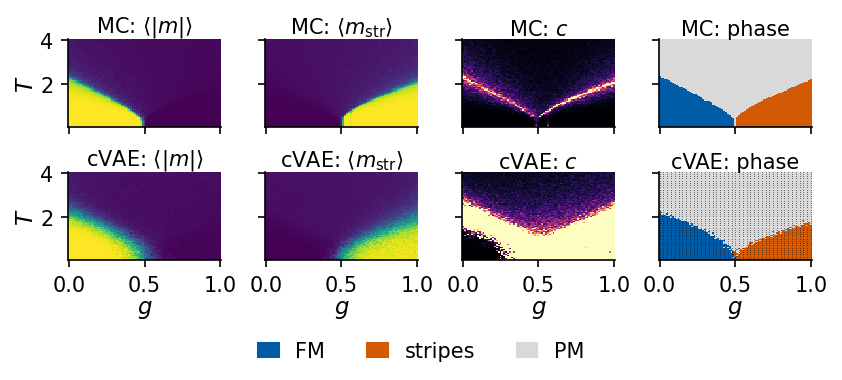

colour scales: <|m|> and <m_str> from 0 (dark) to 1 (yellow); c from 0 to 2.2 (99th percentile of Monte Carlo)


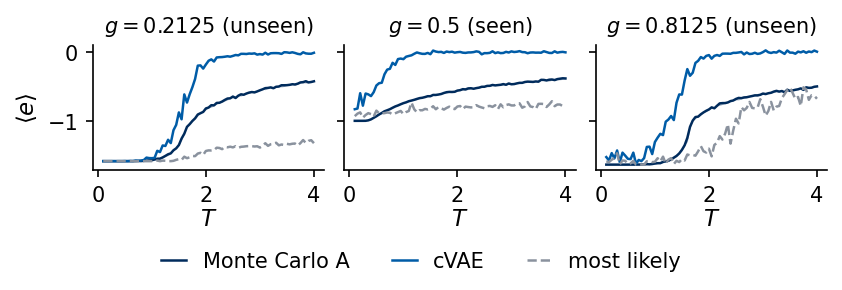

In [22]:
pcol = ListedColormap([blue, orange, "#D9D9D9"])                      # FM, stripes, PM
vmax_c = np.percentile(M_A["c"], 99)
from matplotlib.patches import Patch
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(2, 4, figsize=(5.5, 2.45), sharex=True, sharey=True, layout="constrained")
    for r, (M, PH, nm) in enumerate([(M_A, PH_A, "MC"), (M_syn, PH_syn, "cVAE")]):
        for k, (key, title, cm, vmax) in enumerate([("m", r"$\langle|m|\rangle$", "viridis", 1),
                                                   ("m_str", r"$\langle m_{\rm str}\rangle$", "viridis", 1),
                                                   ("c", "$c$", "magma", vmax_c)]):
            ax[r, k].pcolormesh(g_grid, TJ, M[key].T, shading="nearest", cmap=cm, vmin=0, vmax=vmax, rasterized=True)
            ax[r, k].set_title(f"{nm}: {title}", fontsize=10, pad=2)
        ax[r, 3].pcolormesh(g_grid, TJ, PH.T, shading="nearest", cmap=pcol, vmin=-0.5, vmax=2.5, rasterized=True)
        ax[r, 3].set_title(f"{nm}: phase", fontsize=10, pad=2)
    gs_, ts_ = np.where(seen)
    ax[1, 3].plot(g_grid[gs_], TJ[ts_], ",", color="k", alpha=0.5)          # seen conditions marked on the synthetic phase map
    for a in ax[:, 0]: a.set_ylabel("$T$", labelpad=1)
    for a in ax[1]: a.set_xlabel("$g$", labelpad=1); a.set_xticks([0, 0.5, 1])
    fig.legend([Patch(color=c_) for c_ in [blue, orange, "#D9D9D9"]], ["FM", "stripes", "PM"], loc="outside lower center",
               ncol=3, handlelength=1.0)
    save(fig, "gen_l6_j1j2_maps.png"); plt.show()
print(f"colour scales: <|m|> and <m_str> from 0 (dark) to 1 (yellow); c from 0 to {vmax_c:.1f} (99th percentile of Monte Carlo)")
NUMBERS["j1j2_c_vmax"] = round(float(vmax_c), 1)

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 1.85), layout="constrained", sharey=True)
    for a, gv in zip(ax, [0.2125, 0.5, 0.8125]):                     # g = 0.2125, 0.8125 are not on the training grid
        i = int(np.argmin(np.abs(g_grid - gv)))
        a.fill_between(TJ, np.minimum(M_A["e"][i], M_B["e"][i]), np.maximum(M_A["e"][i], M_B["e"][i]), color=navy, alpha=0.3, lw=0)
        a.plot(TJ, M_A["e"][i], color=navy, lw=1.2, label="Monte Carlo A")
        a.plot(TJ, M_syn["e"][i], color=blue, lw=1.2, label="cVAE")
        a.plot(TJ, M_ml["e"][i], "--", color=grey, lw=1.2, label="most likely")
        a.set_title(f"$g={g_grid[i]:.4g}$" + (" (seen)" if seen[i].any() else " (unseen)"), fontsize=10)
        a.set_xlabel("$T$", labelpad=1)
    ax[0].set_ylabel(r"$\langle e\rangle$")
    fig.legend(*ax[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, handlelength=1.2)
    save(fig, "gen_l6_j1j2_energy.png"); plt.show()

### 4.1 Interpolation of the phase diagram

The phase classifier trained on real data assigns the synthetic snapshots to the same phase as the Monte Carlo snapshots at 95.4% of the grid
points, compared with 99.7% for real against real, and it does so equally at seen and at unseen $(g,T)$: the generator interpolates the phase
diagram. The phase boundary of the synthetic data is smeared, and near $g=1/2$ and close to the transition lines the two maps differ. The order
parameters $\langle|m|\rangle$ and $\langle m_{\rm str}\rangle$ are reproduced within a few noise units, and the two stripe orientations are
generated with equal frequency, as in the Monte Carlo data.

The energy fails as in the Ising case. In the paramagnet the synthetic $\langle e\rangle\approx0$, the value for independent spins, while the
Monte Carlo energy shows the short-range correlations of the paramagnet; the specific heat is wrong by orders of magnitude. The most likely
configurations are ordered almost everywhere, so the classifier sees ferromagnets or stripes deep in the paramagnet and agrees with `S_A` at only
35% of the grid points.

<hr/>
## 5. Synthetic data and thermodynamics

The table below collects all numbers of the lab. Every test is run on the second real held-out set `S_B`, which gives the noise level, and on
the synthetic data at the same conditions; for the noise ratios $R$, a value of 1 means "as close to `S_A` as an independent Monte Carlo set".

In [23]:
def row(name, values, fmt="{:>9}"):
    print(f"{name:42s}" + "".join(fmt.format(v) for v in values))

print("2D Ising, L = 30" + " " * 26 + "".join(f"{n:>9}" for n in ["MC B", "cVAE", "+Z2", "+p(z|T)", "most lik."]))
cols_I = ["Monte Carlo B", "cVAE", "cVAE+Z2", BEST, ML]
row("regressor RMSE of T_hat", [f"{rmse(EVAL[n][0]):.2f}" for n in cols_I])
for k, lab in [("e", "<e>"), ("m", "<|m|>"), ("c", "c"), ("chi", "chi"), ("U4", "U4"), ("W1e", "W1 of P(e)"), ("W1m", "W1 of P(m)"),
               ("GL2", "G(L/2)")]:
    row(f"noise ratio R for {lab}", [f"{NUMBERS[f'ising_R_{n}'][k]:.1f}" for n in cols_I])
row("C2ST accuracy at T = 1.8 / T_c / 3.0", ["/".join(f"{a:.2f}" for a in NUMBERS[f"ising_c2st_{'real vs real' if n == 'Monte Carlo B' else n}"])
                                             for n in cols_I], "{:>16}")
print()
print("J1-J2, L = 32: fraction of grid points with the majority phase of S_A   (all / seen / unseen)")
print(f"  {'real S_B':32s} {agree_AB:.3f} / {np.mean((PH_B == PH_A)[seen]):.3f} / {np.mean((PH_B == PH_A)[~seen]):.3f}")
for n in [JNAME, JNAME + " (most likely)"]:
    print(f"  {n:32s} " + " / ".join(f"{v:.3f}" for v in NUMBERS[f"j1j2_phase_agree_{n}"]))
print("J1-J2 noise ratios R (seen / unseen):  " + ",  ".join(f"{k}: {a} / {b}" for k, (a, b) in NUMBERS[f"j1j2_R_{JNAME}"].items()))

2D Ising, L = 30                               MC B     cVAE      +Z2  +p(z|T)most lik.
regressor RMSE of T_hat                        0.12     0.98     0.84     0.62     0.71
noise ratio R for <e>                           1.0     60.0     50.0     34.8     39.6
noise ratio R for <|m|>                         1.0     13.3     10.8      2.8      9.6
noise ratio R for c                             1.0    155.4    146.1     39.0      6.6
noise ratio R for chi                           1.0     11.8      9.7      2.0      3.7
noise ratio R for U4                            1.0      2.1      1.7      4.2      3.2
noise ratio R for W1 of P(e)                    1.0     38.1     31.9     21.6     24.5
noise ratio R for W1 of P(m)                    1.0      3.3      2.8      1.3      2.8
noise ratio R for G(L/2)                        1.0     15.0     12.4      3.0     11.1
C2ST accuracy at T = 1.8 / T_c / 3.0        0.50/0.53/0.50  0.95/0.94/0.99  0.95/0.98/1.00  0.73/0.95/0.98  1.00/0.98/0.

<hr/>
## Summary

A cVAE trained on Monte Carlo data reproduces what the networks trained on real data look at: the phase, the order parameter and its distribution, and the position of the transition; for the $J_1$–$J_2$ model it does so also at conditions $(g,T)$ it has never seen, interpolating the phase diagram. Two ingredients were needed for this, and both come from physics: the $\mathbb Z_2$ symmetry of $H$ imposed by construction, and a prior $p_\psi(\mathbf z|T)$ that depends on the condition, so that $\mathbf z$ is drawn from the region of latent space that belongs to the requested temperature.

The cVAE does not reproduce what the Hamiltonian measures locally: the energy $\langle e\rangle$, its fluctuations (the specific heat $c$) and $P(e)$. Generating at temperature $T$ means drawing $\mathbf z$ and then every spin independently from its probability $\sigma(\ell_i)$; given $\mathbf z$ the decoder is a product over sites, a mean-field-like distribution, and nearest-neighbour correlations beyond what the 16 latent variables carry are lost, while Monte Carlo, a Markov chain whose stationary distribution is exactly $e^{-\beta H}/Z$, keeps them. A classifier two-sample test detects the difference at every temperature. Synthetic configurations can therefore be useful for questions about the phase, but they are not samples of $e^{-\beta H}/Z$ and cannot replace Monte Carlo for thermodynamics.

### Exercises

1. Increase the latent dimension from 16 to 64. Which tests improve? Does the energy?
2. Replace the dense decoder by a convolutional one. The spins are still independent given $\mathbf z$: what changes, and what cannot?
3. Train the $J_1$–$J_2$ cVAE without the $\mathbb Z_2$ symmetry and without the conditional prior and repeat the phase and stripe-orientation tests.

### References
* D. P. Kingma, M. Welling, *Auto-Encoding Variational Bayes*, [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)
* K. Sohn, H. Lee, X. Yan, *Learning Structured Output Representation using Deep Conditional Generative Models*, Advances in Neural
  Information Processing Systems 28 (NeurIPS 2015), [proceedings](https://papers.nips.cc/paper_files/paper/2015/hash/8d55a249e6baa5c06772297520da2051-Abstract.html)
* D. Lopez-Paz, M. Oquab, *Revisiting Classifier Two-Sample Tests*, [arXiv:1610.06545](https://arxiv.org/abs/1610.06545)
* R. H. Swendsen, J.-S. Wang, *Nonuniversal critical dynamics in Monte Carlo simulations*, Phys. Rev. Lett. **58**, 86 (1987), [doi:10.1103/PhysRevLett.58.86](https://doi.org/10.1103/PhysRevLett.58.86)
* L. Onsager, *Crystal Statistics. I.*, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117)
* C. N. Yang, *The Spontaneous Magnetization of a Two-Dimensional Ising Model*, Phys. Rev. **85**, 808 (1952), [doi:10.1103/PhysRev.85.808](https://doi.org/10.1103/PhysRev.85.808)

In [24]:
NUMBERS["total_seconds"] = round(time.time() - T_START)
with open(f"{OUT}/numbers_lab025.json", "w") as f:
    json.dump(NUMBERS, f, indent=1)
J = NUMBERS
B, V, Z = "cVAE+Z2+p(z|T)", "cVAE", "cVAE+Z2"
JN = "cVAE+Z2+p(z|g,T)"
f1 = lambda x: f"{x:.1f}" if x < 100 else f"{x:.0f}"; f2 = lambda x: f"{x:.2f}"; f3 = lambda x: f"{x:.3f}"
pc = lambda x: f"{100 * x:.0f}\\,\\%"; pc1 = lambda x: f"{100 * x:.1f}\\,\\%"
out = {}
for tag, n in [("MC", "Monte Carlo A"), ("MCB", "Monte Carlo B"), ("V", V), ("Z", Z), ("P", B), ("ML", ML)]:
    out[f"rmse{tag}"], out[f"confmin{tag}"] = f2(J[f"ising_rmse_{n}"]), f2(J[f"ising_confmin_{n}"])
for tag, n in [("V", V), ("Z", Z), ("P", B), ("ML", ML)]:
    for k, v in J[f"ising_R_{n}"].items():
        out[f"R{k}{tag}"] = f1(v)
for tag, n in [("MC", "Monte Carlo A"), ("V", V), ("Z", Z), ("P", B)]:
    out[f"mix{tag}"], out[f"mpos{tag}"] = pc(J[f"ising_mixed_{n}"]), f2(J[f"ising_mpos_{n}"])
for tag, n in [("RR", "real vs real"), ("V", V), ("Z", Z), ("P", B), ("ML", ML)]:
    for i, v in enumerate(J[f"ising_c2st_{n}"]):
        out[f"ctwo{tag}{'abc'[i]}"] = f2(v)
for tag, n in [("MC", "Monte Carlo A"), ("V", V), ("Z", Z), ("P", B)]:
    for i, v in enumerate(J[f"ising_dnn_{n}"]):
        out[f"dnn{tag}{'abc'[i]}"] = f2(v)
for tag, n in [("V", V), ("Z", Z), ("P", B)]:
    out[f"elbotr{tag}"], out[f"elbote{tag}"] = f"{J[f'ising_elbo_train_{n}']:.0f}", f"{J[f'ising_elbo_test_{n}']:.0f}"
    out[f"active{tag}"], out[f"recacc{tag}"] = str(J[f"ising_active_{n}"]), pc(J[f"ising_recacc_{n}"])
for key in ["e", "m", "c"]:
    t = J[f"ising_{key}_table"]
    for i in range(len(t["T"])):
        for tag, n in [("MC", "Monte Carlo A"), ("P", B), ("ML", ML)]:
            out[f"{key}tab{tag}{'abcdef'[i]}"] = f2(t[n][i])
        out[f"Ttab{'abcdef'[i]}"] = f2(t["T"][i])
out["noiseE"] = f3(J["ising_noise_e"])
out["phAB"] = pc1(J["j1j2_phase_agree_AB"])
for tag, n in [("P", JN), ("ML", JN + " (most likely)")]:
    a, s_, u = J[f"j1j2_phase_agree_{n}"]
    out[f"ph{tag}"], out[f"ph{tag}seen"], out[f"ph{tag}unseen"] = pc1(a), pc1(s_), pc1(u)
for k, (s_, u) in J[f"j1j2_R_{JN}"].items():
    out[f"jR{k.replace('_', '')}seen"], out[f"jR{k.replace('_', '')}unseen"] = f1(s_), f1(u)
out["orientMC"], out["orientP"] = f2(J["j1j2_orient_Monte Carlo A"]), f2(J[f"j1j2_orient_{JN}"])
out["jelbotr"], out["jelboseen"], out["jelbounseen"] = (f"{J['j1j2_elbo_train']:.0f}", f"{J['j1j2_elbo_seen']:.0f}",
                                                        f"{J['j1j2_elbo_unseen']:.0f}")
out["jactive"], out["totalmin"] = str(J["j1j2_active"]), f"{J['total_seconds'] / 60:.0f}"
out["jcvmax"] = f"{J['j1j2_c_vmax']:.1f}"
for Tv, (G_s, G_m, G_mc) in J["mf_G1"].items():
    tag = "a" if Tv == "1.80" else "b"
    out[f"mfGs{tag}"], out[f"mfGm{tag}"], out[f"mfGmc{tag}"] = f3(G_s), f3(G_m), f3(G_mc)
with open("../beamer/sections/nb_numbers_lab025.tex", "w") as f:
    for k, v in out.items():
        f.write(f"\\setnbnum{{p{k}}}{{{v}}}\n")
print("numbers written")

numbers written
